# Subscription Revenue & Customer Lifecycle Intelligence
## Real KKBox subscriber data: segmentation, behavioral trajectories, churn prediction and retention prioritization

### Project objective
This portfolio project demonstrates how customer analytics can move from **describing subscriber behavior** to **prioritizing commercial action**.

Using the real anonymized KKBox churn-competition dataset, the analysis combines membership attributes, transaction history and daily listening behavior to answer five business questions:

1. Which subscriber groups have meaningfully different commercial and engagement profiles?
2. Does recent behavioral trajectory add information beyond static segmentation?
3. How accurately can near-term churn be predicted?
4. Are the predicted probabilities sufficiently calibrated for economic decision-making?
5. Under limited retention capacity, should the business target the most likely churners or the greatest subscription value at risk?

### Key modeling components
- point-in-time feature engineering with a **2017-02-28** cutoff
- static subscriber segmentation using K-means
- exploratory DTW time-series clustering and a documented pivot when separation is weak
- interpretable engagement-trajectory clustering
- logistic-regression baseline and LightGBM challenger
- probability calibration
- annualized subscription value at risk
- capacity-constrained retention simulation

> **Data note:** KKBox is a consumer subscription business. The project therefore uses **Monthly Subscription Value (MSV)** and **Annualized Subscription Value (ASV)** as analytical run-rate proxies. These are not official KKBox MRR/ARR metrics.

> **Reproducibility note:** The raw Kaggle competition data is not redistributed with this notebook. The notebook downloads the required files after the user authenticates with Kaggle and has accepted the competition rules.

### Public-repository note
This notebook is designed for a public code portfolio. Raw KKBox competition files are **not included**, Kaggle credentials are requested interactively, and saved notebook outputs avoid publishing row-level subscriber identifiers or records. To reproduce the analysis, users must join the Kaggle competition and accept its data-use rules.


### How to read this notebook

The project is intentionally organized as a business decision pipeline rather than as a sequence of unrelated models:

**Data -> customer features -> segmentation -> engagement trajectory -> churn probability -> calibrated risk -> value-at-risk -> retention prioritization**

A useful way to read it is to ask one question at each stage:

- **Data preparation:** What information was actually available before churn was observed?
- **Segmentation:** What broad customer types exist without using the churn label?
- **Trajectory analysis:** Is recent behavior stable, intermittent or changing?
- **Prediction:** Which individual subscribers are most likely to churn?
- **Calibration:** Can the predicted probability be treated as a probability rather than only a ranking score?
- **Commercial decisioning:** If retention capacity is limited, who should be contacted first?

> **Important distinction:** clustering and churn prediction solve different problems. Clustering is descriptive and helps explain customer structure; supervised modeling is predictive and estimates individual churn risk.


## 1. Environment and reproducibility setup

All third-party packages are installed up front so the notebook can be run top-to-bottom in a fresh Google Colab session. Random seeds and working directories are defined once and reused throughout the analysis.

### 1.1 Install dependencies

`tslearn` supports the DTW experiment, `lightgbm` is the main nonlinear churn model, and `shap` is used for model interpretation.

In [1]:
!pip -q install -U kaggle py7zr tslearn lightgbm shap

import os
import gc
import getpass
import subprocess
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

BASE_DIR = Path("/content/kkbox")
RAW_DIR = BASE_DIR / "raw"
WORK_DIR = BASE_DIR / "work"
RAW_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_CUTOFF = pd.Timestamp("2017-02-28")
SAMPLE_SIZE = 25_000
CHUNK_SIZE = 500_000
DTW_SAMPLE_SIZE = 3_000

print("Environment ready")
print("Raw data directory:", RAW_DIR)
print("Feature cutoff:", FEATURE_CUTOFF.date())
print("Portfolio sample size:", f"{SAMPLE_SIZE:,}")

Environment ready
Raw data directory: /content/kkbox/raw
Feature cutoff: 2017-02-28
Portfolio sample size: 25,000


## 2. Acquire the real KKBox data from Kaggle

The notebook uses four competition files:

- `members_v3.csv.7z`
- `train_v2.csv.7z`
- `transactions.csv.7z`
- `user_logs.csv.7z`

The current Kaggle API uses an access token. The token is entered interactively with `getpass`, so it is not written into the notebook.

> **Data handling:** The repository should contain the notebook/code only, not the KKBox raw CSV/7z files. This notebook downloads the competition data at runtime after the user authenticates and has accepted the competition rules.


In [2]:
# Authenticate securely with the current Kaggle API token.

token = getpass.getpass("Paste your NEW Kaggle API token: ").strip()

kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)

token_file = kaggle_dir / "access_token"

token_file.write_text(token)

os.chmod(token_file, 0o600)

print("Kaggle token saved securely.")

Paste your NEW Kaggle API token: ··········
Kaggle token saved securely.


In [3]:
# Verify that the competition files are visible before attempting large downloads.

COMPETITION = "kkbox-churn-prediction-challenge"

result = subprocess.run(
    [
        "kaggle",
        "competitions",
        "files",
        "-c",
        COMPETITION
    ],
    capture_output=True,
    text=True
)

print("RETURN CODE:", result.returncode)
print(result.stdout)

if result.stderr:
    print("\nERROR:")
    print(result.stderr)

RETURN CODE: 0
name                                 size  creationDate                
-----------------------------  ----------  --------------------------  
WSDMChurnLabeller.scala              7050  2019-12-12 00:03:26.134000  
members_v3.csv.7z               242308558  2019-12-12 00:03:32.359000  
sample_submission_v2.csv.7z      30666957  2019-12-12 00:03:30.171000  
sample_submission_zero.csv.7z    32828332  2019-12-12 00:03:30.262000  
train.csv.7z                     33563098  2019-12-12 00:03:30.206000  
train_v2.csv.7z                  32818991  2019-12-12 00:03:30.479000  
transactions.csv.7z             707508779  2019-12-12 00:03:48.335000  
transactions_v2.csv.7z           48850410  2019-12-12 00:03:38.591000  
user_logs.csv.7z               7136060375  2019-12-12 00:08:24.997000  
user_logs_v2.csv.7z             685951221  2019-12-12 00:06:08.289000  



In [4]:
# Download only the four files required for this analysis.

FILES_NEEDED = [
    "members_v3.csv.7z",
    "train_v2.csv.7z",
    "transactions.csv.7z",
    "user_logs.csv.7z"
]

for filename in FILES_NEEDED:

    archive_path = RAW_DIR / filename

    if archive_path.exists():
        print(f"Already downloaded: {filename}")
        continue

    print(f"\nDownloading: {filename}")

    result = subprocess.run(
        [
            "kaggle",
            "competitions",
            "download",
            "-c",
            COMPETITION,
            "-f",
            filename,
            "-p",
            str(RAW_DIR)
        ],
        capture_output=True,
        text=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(
            f"Download failed for {filename}"
        )

print("\nAll downloads completed.")


Downloading: members_v3.csv.7z



Downloading: train_v2.csv.7z



Downloading: transactions.csv.7z



Downloading: user_logs.csv.7z



All downloads completed.


### 2.1 Extract archives and normalize file locations

Some KKBox archives contain nested internal folders. The extraction logic therefore searches recursively for each expected CSV and moves it into the standard raw-data directory. This avoids hard-coding archive-internal paths.

In [5]:
# Extract each archive and move nested CSVs into RAW_DIR.

import py7zr
from pathlib import Path
import shutil

for archive_name in FILES_NEEDED:

    archive_path = RAW_DIR / archive_name
    expected_name = archive_name.replace(".7z", "")
    expected_path = RAW_DIR / expected_name

    if expected_path.exists():
        print(f"Already ready: {expected_name}")
        continue

    print(f"\nExtracting: {archive_name}")

    with py7zr.SevenZipFile(archive_path, mode="r") as archive:
        print("Contains:", archive.getnames())
        archive.extractall(path=RAW_DIR)

    # Search recursively for the expected CSV
    matches = list(RAW_DIR.rglob(expected_name))

    if not matches:
        raise FileNotFoundError(
            f"Could not find {expected_name} after extracting {archive_name}"
        )

    found = matches[0]

    # Move nested file to standard RAW_DIR location
    if found != expected_path:
        print(f"Moving:")
        print(f"  {found}")
        print(f"-> {expected_path}")

        shutil.move(str(found), str(expected_path))

    print(f"Ready: {expected_path.name}")

print("\nAll extraction steps completed.")


Extracting: members_v3.csv.7z
Contains: ['members_v3.csv']
Ready: members_v3.csv

Extracting: train_v2.csv.7z
Contains: ['data/churn_comp_refresh/train_v2.csv']
Moving:
  /content/kkbox/raw/data/churn_comp_refresh/train_v2.csv
-> /content/kkbox/raw/train_v2.csv
Ready: train_v2.csv

Extracting: transactions.csv.7z
Contains: ['transactions.csv']
Ready: transactions.csv

Extracting: user_logs.csv.7z
Contains: ['user_logs.csv']
Ready: user_logs.csv

All extraction steps completed.


## 3. Define the churn cohort and reproducible portfolio sample

`train_v2.csv` contains the March-2017 churn labels. The full cohort contains almost one million subscribers, so the notebook takes a **25,000-subscriber stratified sample** that preserves the original churn prevalence. This keeps the project practical in Colab while retaining real customer records.

### Why a stratified 25,000-subscriber sample?

The full labeled cohort is close to one million subscribers and the behavioral logs are much larger still. A 25,000-subscriber sample keeps the project reproducible in a standard Colab session while preserving real subscriber histories.

`stratify=y` is conceptually important: it preserves the original churn prevalence, so the sample remains representative of the class imbalance that the model must solve. The sample is therefore a computational design choice, not an attempt to artificially balance churn and non-churn customers.


In [6]:
# Load the full March-2017 churn cohort and inspect target prevalence.
# Subscriber identifiers are used internally but are not printed in public outputs.
labels = pd.read_csv(
    RAW_DIR / "train_v2.csv",
    usecols=["msno", "is_churn"]
)

print("Full label cohort:", labels.shape)
print("\nChurn counts:")
print(labels["is_churn"].value_counts())
print("\nChurn rate:", round(labels["is_churn"].mean(), 4))

Full label cohort: (970960, 2)

Churn counts:
is_churn
0    883630
1     87330
Name: count, dtype: int64

Churn rate: 0.0899


In [7]:
# Draw a reproducible stratified sample that preserves the churn rate.
SAMPLE_SIZE = 25_000
RANDOM_STATE = 42

def stratified_sample(df, n, target="is_churn", random_state=42):
    if n >= len(df):
        return df.copy()

    sampled_parts = []
    for target_value, group in df.groupby(target):
        share = len(group) / len(df)
        number_to_take = min(int(round(n * share)), len(group))
        sampled_parts.append(
            group.sample(n=number_to_take, random_state=random_state)
        )

    sampled = pd.concat(sampled_parts, ignore_index=True)
    sampled = sampled.sample(frac=1, random_state=random_state).reset_index(drop=True)
    return sampled.iloc[:n].copy()

sample_labels = stratified_sample(labels, SAMPLE_SIZE, random_state=RANDOM_STATE)
sample_ids = set(sample_labels["msno"])

print("Portfolio sample:", sample_labels.shape)
print("Sample churn rate:", round(sample_labels["is_churn"].mean(), 4))
print("\nSample churn counts:")
print(sample_labels["is_churn"].value_counts())

Portfolio sample: (25000, 2)
Sample churn rate: 0.09

Sample churn counts:
is_churn
0    22751
1     2249
Name: count, dtype: int64


## 4. Member profile features

Member attributes provide demographic and acquisition context. Coverage is incomplete for some fields, especially age and gender, so the notebook keeps missingness visible rather than forcing artificial values.

Ages outside the plausible range 15-90 are treated as missing. Registration tenure is calculated relative to the feature cutoff.

In [8]:
# Stream the large member file in chunks and keep only sampled subscribers.
MEMBER_COLS = [
    "msno", "city", "bd", "gender", "registered_via", "registration_init_time"
]

member_parts = []
for chunk in pd.read_csv(
    RAW_DIR / "members_v3.csv",
    usecols=MEMBER_COLS,
    chunksize=500_000
):
    matched = chunk[chunk["msno"].isin(sample_ids)].copy()
    if len(matched) > 0:
        member_parts.append(matched)

members = pd.concat(member_parts, ignore_index=True)
print("Matched members:", members.shape)
print("Member columns:", [c for c in members.columns if c != "msno"])

Matched members: (22107, 6)
Member columns: ['city', 'bd', 'gender', 'registered_via', 'registration_init_time']


In [9]:
# Parse registration dates and create cleaned age / registration-tenure features.

members["registration_init_time"] = pd.to_datetime(
    members["registration_init_time"]
    .astype("Int64")
    .astype(str),
    format="%Y%m%d",
    errors="coerce"
)

# Keep only plausible ages
members["age_clean"] = members["bd"].where(
    members["bd"].between(15, 90)
)

FEATURE_CUTOFF = pd.Timestamp("2017-02-28")

members["registration_tenure_days"] = (
    FEATURE_CUTOFF
    - members["registration_init_time"]
).dt.days

In [10]:
# Audit member coverage and missingness.

print("Members:", len(members))
print(
    "Matched share:",
    round(len(members) / len(sample_labels), 3)
)

print("\nMissing values:")
display(
    members.isna()
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print("\nAge summary:")
display(
    members["age_clean"].describe()
)

Members: 22107
Matched share: 0.884

Missing values:


,0
age_clean,54.79
gender,54.74
city,0.00
msno,0.00
bd,0.00
registered_via,0.00
registration_init_time,0.00
registration_tenure_days,0.00



Age summary:


,age_clean
count,9994.000000
mean,29.905343
std,8.949923
min,15.000000
25%,24.000000
50%,28.000000
75%,34.000000
max,90.000000


## 5. Transaction and subscription-value engineering

The transaction table provides the commercial layer of the project. Only transactions available on or before **2017-02-28** are used.

### Subscription value proxy
For plans with a positive duration:

**MSV = (actual amount paid / payment plan days) × 30.4375**

**ASV = MSV × 12**

These normalized values allow subscribers on different plan lengths to be compared on a common monthly / annualized run-rate basis.

### How to interpret MSV and ASV

These variables make plans with different durations comparable. For example, a 30-day payment and a longer-duration payment cannot be compared directly from the raw transaction amount alone.

- **MSV** normalizes the latest paid amount to an average month.
- **ASV** annualizes that run-rate for prioritization.

They are **value proxies**, not accounting measures and not customer lifetime value. Later, ASV is multiplied by calibrated churn probability to estimate relative economic exposure.


In [11]:
# Stream historical transactions and keep only sampled subscribers.
TX_COLS = [
    "msno", "payment_method_id", "payment_plan_days", "plan_list_price",
    "actual_amount_paid", "is_auto_renew", "transaction_date",
    "membership_expire_date", "is_cancel"
]

transaction_parts = []
for chunk in pd.read_csv(
    RAW_DIR / "transactions.csv",
    usecols=TX_COLS,
    chunksize=500_000
):
    matched = chunk[chunk["msno"].isin(sample_ids)].copy()
    if len(matched) > 0:
        transaction_parts.append(matched)

transactions = pd.concat(transaction_parts, ignore_index=True)
print("Matched transactions:", transactions.shape)
print("Unique subscribers:", transactions["msno"].nunique())

Matched transactions: (389340, 9)
Unique subscribers: 24933


In [12]:
# Parse transaction and expiry dates.

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"]
    .astype("Int64")
    .astype(str),
    format="%Y%m%d",
    errors="coerce"
)

transactions["membership_expire_date"] = pd.to_datetime(
    transactions["membership_expire_date"]
    .astype("Int64")
    .astype(str),
    format="%Y%m%d",
    errors="coerce"
)

In [13]:
# Enforce the point-in-time feature cutoff to prevent future information from entering the model.

FEATURE_CUTOFF = pd.Timestamp("2017-02-28")

transactions = transactions[
    transactions["transaction_date"] <= FEATURE_CUTOFF
].copy()

print("Transactions after cutoff:", transactions.shape)

print(
    "Date range:",
    transactions["transaction_date"].min(),
    "to",
    transactions["transaction_date"].max()
)

Transactions after cutoff: (389340, 9)
Date range: 2015-01-01 00:00:00 to 2017-02-28 00:00:00


In [14]:
# Normalize payment amounts into monthly and annualized subscription-value proxies.

transactions["monthly_subscription_value"] = np.where(
    transactions["payment_plan_days"] > 0,
    (
        transactions["actual_amount_paid"]
        / transactions["payment_plan_days"]
        * 30.4375
    ),
    np.nan
)

transactions["annualized_subscription_value"] = (
    transactions["monthly_subscription_value"] * 12
)

transactions["discount_value"] = (
    transactions["plan_list_price"]
    - transactions["actual_amount_paid"]
)

transactions["discount_rate"] = np.where(
    transactions["plan_list_price"] > 0,
    transactions["discount_value"]
    / transactions["plan_list_price"],
    0
)

In [15]:
# Sanity-check engineered subscription-value fields without publishing row-level records.
value_check_cols = [
    "payment_plan_days", "plan_list_price", "actual_amount_paid",
    "monthly_subscription_value", "annualized_subscription_value",
    "is_auto_renew", "is_cancel"
]

display(
    transactions[value_check_cols]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .T
    .round(3)
)

,count,mean,std,min,25%,50%,75%,max
payment_plan_days,389340.0,29.724,16.392,0.0,30.000,30.000,30.000,450.000
plan_list_price,389340.0,132.161,74.360,0.0,99.000,149.000,149.000,2000.000
actual_amount_paid,389340.0,136.911,71.045,0.0,99.000,149.000,149.000,2000.000
monthly_subscription_value,374309.0,134.138,26.838,0.0,100.444,151.173,151.173,182.625
annualized_subscription_value,374309.0,1609.661,322.053,0.0,1205.325,1814.075,1814.075,2191.500
is_auto_renew,389340.0,0.920,0.271,0.0,1.000,1.000,1.000,1.000
is_cancel,389340.0,0.016,0.127,0.0,0.000,0.000,0.000,1.000


### 5.1 Aggregate transaction behavior

The subscriber-level transaction mart captures:
- lifetime transaction frequency and tenure
- payment amount variability
- auto-renew and cancellation behavior
- discount behavior
- recent 30-day and 90-day transaction activity
- latest subscription state and days to expiry

In [16]:
# Create recent transaction windows and identify the latest known transaction per subscriber.

transactions = transactions.sort_values(
    ["msno", "transaction_date"]
).copy()

transactions["days_before_cutoff"] = (
    FEATURE_CUTOFF - transactions["transaction_date"]
).dt.days

tx90 = transactions[
    transactions["transaction_date"]
    >= FEATURE_CUTOFF - pd.Timedelta(days=89)
].copy()

tx30 = transactions[
    transactions["transaction_date"]
    >= FEATURE_CUTOFF - pd.Timedelta(days=29)
].copy()

latest_tx = (
    transactions
    .sort_values(["msno", "transaction_date"])
    .groupby("msno")
    .tail(1)
    .copy()
)

latest_tx["days_to_expiry"] = (
    latest_tx["membership_expire_date"]
    - FEATURE_CUTOFF
).dt.days

In [17]:
# Aggregate full-history transaction behavior.

tx_all_agg = (
    transactions
    .groupby("msno")
    .agg(
        transaction_count=("transaction_date", "count"),
        avg_amount_paid=("actual_amount_paid", "mean"),
        std_amount_paid=("actual_amount_paid", "std"),
        avg_plan_days=("payment_plan_days", "mean"),
        avg_discount_rate=("discount_rate", "mean"),
        max_discount_rate=("discount_rate", "max"),
        cancellation_count=("is_cancel", "sum"),
        auto_renew_rate=("is_auto_renew", "mean"),
        first_transaction_date=("transaction_date", "min"),
        last_transaction_date=("transaction_date", "max")
    )
    .reset_index()
)

In [18]:
# Aggregate 90-day transaction behavior.

tx90_agg = (
    tx90
    .groupby("msno")
    .agg(
        tx_count_90d=("transaction_date", "count"),
        amount_paid_90d=("actual_amount_paid", "sum"),
        cancel_count_90d=("is_cancel", "sum")
    )
    .reset_index()
)

In [19]:
# Aggregate 30-day transaction behavior.

tx30_agg = (
    tx30
    .groupby("msno")
    .agg(
        tx_count_30d=("transaction_date", "count"),
        amount_paid_30d=("actual_amount_paid", "sum"),
        cancel_count_30d=("is_cancel", "sum")
    )
    .reset_index()
)

In [20]:
# Keep the latest subscription state with presentation-friendly feature names.

latest_keep = latest_tx[
    [
        "msno",
        "payment_method_id",
        "payment_plan_days",
        "actual_amount_paid",
        "plan_list_price",
        "is_auto_renew",
        "is_cancel",
        "membership_expire_date",
        "days_to_expiry",
        "monthly_subscription_value",
        "annualized_subscription_value",
        "discount_rate"
    ]
].rename(
    columns={
        "payment_method_id": "latest_payment_method_id",
        "payment_plan_days": "latest_payment_plan_days",
        "actual_amount_paid": "latest_amount_paid",
        "plan_list_price": "latest_plan_list_price",
        "is_auto_renew": "latest_is_auto_renew",
        "is_cancel": "latest_is_cancel",
        "membership_expire_date": "latest_membership_expire_date",
        "discount_rate": "latest_discount_rate"
    }
)

In [21]:
# Merge full-history, 90-day, 30-day and latest-state features.

tx_features = (
    tx_all_agg
    .merge(
        tx90_agg,
        on="msno",
        how="left"
    )
    .merge(
        tx30_agg,
        on="msno",
        how="left"
    )
    .merge(
        latest_keep,
        on="msno",
        how="left"
    )
)

In [22]:
# Missing recent-event counts mean no observed recent event, so fill those counts with zero.

recent_cols = [
    "tx_count_90d",
    "amount_paid_90d",
    "cancel_count_90d",
    "tx_count_30d",
    "amount_paid_30d",
    "cancel_count_30d"
]

for col in recent_cols:
    tx_features[col] = tx_features[col].fillna(0)

In [23]:
# Measure observed subscription tenure from the first transaction to the cutoff.

tx_features["subscription_tenure_days"] = (
    FEATURE_CUTOFF
    - tx_features["first_transaction_date"]
).dt.days

In [24]:
# Validate transaction-feature coverage and summarize engineered features.
print("Transaction feature table:", tx_features.shape)
print("Subscribers covered:", tx_features["msno"].nunique())

display(
    tx_features.drop(columns=["msno"], errors="ignore")
    .select_dtypes(include=np.number)
    .describe()
    .T
    .round(3)
    .head(20)
)

Transaction feature table: (24933, 29)
Subscribers covered: 24933


,count,mean,std,min,25%,50%,75%,max
transaction_count,24933.0,15.615,8.507,1.0,8.000,16.000,22.000,48.000
avg_amount_paid,24933.0,149.196,144.376,0.0,99.000,141.091,149.000,1788.000
std_amount_paid,23979.0,21.296,89.009,0.0,0.000,0.000,10.014,1264.307
avg_plan_days,24933.0,33.805,33.036,0.0,28.889,30.000,30.000,450.000
avg_discount_rate,24933.0,0.008,0.048,0.0,0.000,0.000,0.000,1.000
max_discount_rate,24933.0,0.054,0.212,0.0,0.000,0.000,0.000,1.000
cancellation_count,24933.0,0.255,0.562,0.0,0.000,0.000,0.000,9.000
auto_renew_rate,24933.0,0.868,0.319,0.0,1.000,1.000,1.000,1.000
tx_count_90d,24933.0,2.728,0.749,0.0,3.000,3.000,3.000,8.000
amount_paid_90d,24933.0,353.140,119.684,0.0,297.000,298.000,447.000,900.000


## 6. Listening engagement features

`user_logs.csv` is the largest file in the project. It is never loaded in full. Instead, the notebook streams it in chunks, keeps only sampled subscribers, and retains the final 30-day observation window before the cutoff.

The engagement layer measures activity intensity, breadth of listening, completion behavior, inactivity and recent-versus-prior momentum.

In [25]:
# Stream the user-log file in chunks and retain only the 30-day point-in-time window.
LOG_COLS = [
    "msno", "date", "num_25", "num_50", "num_75", "num_985",
    "num_100", "num_unq", "total_secs"
]

log_parts = []
for chunk in pd.read_csv(
    RAW_DIR / "user_logs.csv",
    usecols=LOG_COLS,
    chunksize=500_000
):
    matched = chunk[chunk["msno"].isin(sample_ids)].copy()
    if len(matched) == 0:
        continue

    matched["date"] = pd.to_datetime(
        matched["date"].astype("Int64").astype(str),
        format="%Y%m%d",
        errors="coerce"
    )

    matched = matched[
        matched["date"].between(
            FEATURE_CUTOFF - pd.Timedelta(days=29),
            FEATURE_CUTOFF
        )
    ]

    if len(matched) > 0:
        log_parts.append(matched)

logs30 = pd.concat(log_parts, ignore_index=True)
print("30-day log rows:", logs30.shape)
print("Unique subscribers:", logs30["msno"].nunique())
print("Date range:", logs30["date"].min(), "to", logs30["date"].max())

30-day log rows: (326371, 9)
Unique subscribers: 19521
Date range: 2017-01-30 00:00:00 to 2017-02-28 00:00:00


In [26]:
# Convert raw song counts and listening seconds into interpretable daily engagement measures.

logs30["songs_total"] = (
    logs30["num_25"]
    + logs30["num_50"]
    + logs30["num_75"]
    + logs30["num_985"]
    + logs30["num_100"]
)

logs30["completion_rate"] = np.where(
    logs30["songs_total"] > 0,
    logs30["num_100"] / logs30["songs_total"],
    np.nan
)

logs30["hours_listened"] = (
    logs30["total_secs"] / 3600
)

In [27]:
# Aggregate 30-day engagement behavior.

log30_features = (
    logs30
    .groupby("msno")
    .agg(
        active_days_30d=("date", "nunique"),
        total_hours_30d=("hours_listened", "sum"),
        avg_hours_active_day_30d=("hours_listened", "mean"),
        unique_songs_30d=("num_unq", "sum"),
        songs_completed_30d=("num_100", "sum"),
        avg_completion_rate_30d=("completion_rate", "mean")
    )
    .reset_index()
)

In [28]:
# Build a focused 7-day recent-engagement window.

logs7 = logs30[
    logs30["date"] >= FEATURE_CUTOFF - pd.Timedelta(days=6)
].copy()

log7_features = (
    logs7
    .groupby("msno")
    .agg(
        active_days_7d=("date", "nunique"),
        total_hours_7d=("hours_listened", "sum"),
        unique_songs_7d=("num_unq", "sum")
    )
    .reset_index()
)

In [29]:
# Merge 30-day and 7-day engagement features.

engagement_features = (
    log30_features
    .merge(
        log7_features,
        on="msno",
        how="left"
    )
)

for col in [
    "active_days_7d",
    "total_hours_7d",
    "unique_songs_7d"
]:
    engagement_features[col] = (
        engagement_features[col]
        .fillna(0)
    )

In [30]:
# Compare the latest 7 days with the prior 23 days to capture engagement momentum.

engagement_features["hours_prior_23d"] = (
    engagement_features["total_hours_30d"]
    - engagement_features["total_hours_7d"]
).clip(lower=0)

engagement_features["recent_vs_prior_daily_hours"] = (
    (
        engagement_features["total_hours_7d"] / 7
        + 0.01
    )
    /
    (
        engagement_features["hours_prior_23d"] / 23
        + 0.01
    )
)

In [31]:
# Validate engagement-feature coverage using aggregate summaries only.
print("Engagement feature table:", engagement_features.shape)
print("Subscribers covered:", engagement_features["msno"].nunique())

display(
    engagement_features.drop(columns=["msno"], errors="ignore")
    .describe()
    .T
    .round(3)
)

Engagement feature table: (19521, 12)
Subscribers covered: 19521


,count,mean,std,min,25%,50%,75%,max
active_days_30d,19521.0,16.719,9.117,1.000,9.000,17.000,25.000,30.000
total_hours_30d,19521.0,36.035,47.136,0.000,8.282,21.674,45.220,675.864
avg_hours_active_day_30d,19521.0,1.807,1.757,0.000,0.825,1.340,2.166,55.940
unique_songs_30d,19521.0,478.542,545.982,1.000,123.000,313.000,637.000,7319.000
songs_completed_30d,19521.0,495.756,691.138,0.000,106.000,288.000,612.000,12467.000
avg_completion_rate_30d,19521.0,0.686,0.197,0.000,0.583,0.720,0.829,1.000
active_days_7d,19521.0,4.027,2.376,0.000,2.000,4.000,6.000,7.000
total_hours_7d,19521.0,8.780,13.007,0.000,1.399,4.846,11.052,574.440
unique_songs_7d,19521.0,116.104,143.042,0.000,21.000,71.000,157.000,1891.000
hours_prior_23d,19521.0,27.255,36.327,0.000,5.629,16.002,34.482,515.488


## 7. Build the analytical customer mart

The churn label, member profile, transaction features and engagement features are merged into one subscriber-level table.

Only engagement activity fields are zero-filled where missingness naturally means **no observed activity**. Demographic and commercial unknowns remain missing and are handled later by model-specific imputers.

In [32]:
# Merge the four analytical layers into one customer mart.
customer = (
    sample_labels
    .merge(members, on="msno", how="left")
    .merge(tx_features, on="msno", how="left")
    .merge(engagement_features, on="msno", how="left")
)

print("Customer mart:", customer.shape)
print("Columns:", len(customer.columns))
print("Observed churn rate:", round(customer["is_churn"].mean(), 4))

Customer mart: (25000, 48)
Columns: 48
Observed churn rate: 0.09


In [33]:
# Zero-fill only activity fields where absence means no observed activity.

zero_fill_cols = [
    "active_days_30d",
    "total_hours_30d",
    "unique_songs_30d",
    "songs_completed_30d",
    "active_days_7d",
    "total_hours_7d",
    "unique_songs_7d"
]

for col in zero_fill_cols:
    customer[col] = customer[col].fillna(0)

customer["has_recent_usage"] = (
    customer["active_days_30d"] > 0
).astype(int)

In [34]:
# Audit the final customer mart before modeling.

print("Customers:", len(customer))
print("Churn rate:", round(customer["is_churn"].mean(), 4))

audit = pd.DataFrame({
    "dtype": customer.dtypes.astype(str),
    "missing_n": customer.isna().sum(),
    "missing_pct": (
        customer.isna().mean() * 100
    ).round(2),
    "unique": customer.nunique(dropna=True)
})

display(
    audit
    .sort_values("missing_pct", ascending=False)
    .head(25)
)

Customers: 25000
Churn rate: 0.09


,dtype,missing_n,missing_pct,unique
age_clean,float64,15006,60.02,65
gender,object,14995,59.98,2
recent_vs_prior_daily_hours,float64,5479,21.92,19521
hours_prior_23d,float64,5479,21.92,19058
avg_completion_rate_30d,float64,5479,21.92,18389
avg_hours_active_day_30d,float64,5479,21.92,19519
registration_init_time,datetime64[ns],2893,11.57,3938
bd,float64,2893,11.57,78
city,float64,2893,11.57,21
registration_tenure_days,float64,2893,11.57,3938


# Part II - Unsupervised customer intelligence

## 8. Static subscriber segmentation

Static clustering answers: **Who is the subscriber today?**

The clustering feature set combines subscription value, tenure, payment behavior, renewal/cancellation behavior and recent engagement. The churn label is deliberately excluded.

Cluster count is chosen by comparing:
- Silhouette score (higher is better)
- Davies-Bouldin score (lower is better)
- Calinski-Harabasz score (higher is better)

The final solution uses **five clusters**, which provides the best overall balance of separation and business interpretability.

### Why cluster before building the churn model?

The segmentation stage is deliberately unsupervised. It does **not** use `is_churn` to create the clusters.

The goal is different from prediction: clustering asks whether subscribers naturally form commercially meaningful groups based on value, renewal behavior, tenure and engagement. Churn is inspected only afterward to understand whether those groups differ in business risk.

This gives the final project two complementary lenses:

1. **Segments** explain broad customer types.
2. **The supervised model** predicts individual churn probability.


In [35]:
# Define the static clustering feature set.

cluster_features = [
    "annualized_subscription_value",
    "subscription_tenure_days",
    "transaction_count",
    "tx_count_90d",
    "avg_discount_rate",
    "auto_renew_rate",
    "cancellation_count",
    "days_to_expiry",
    "active_days_30d",
    "total_hours_30d",
    "unique_songs_30d",
    "avg_completion_rate_30d",
    "recent_vs_prior_daily_hours"
]

In [36]:
# Median-impute and standardize clustering features.

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X_cluster = customer[
    cluster_features
].replace(
    [np.inf, -np.inf],
    np.nan
)

imputer = SimpleImputer(
    strategy="median"
)

scaler = StandardScaler()

X_cluster_imputed = imputer.fit_transform(
    X_cluster
)

X_cluster_scaled = scaler.fit_transform(
    X_cluster_imputed
)

print(
    "Clustering matrix:",
    X_cluster_scaled.shape
)

Clustering matrix: (25000, 13)


In [37]:
# Evaluate candidate cluster counts from 2 through 7.

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

cluster_scores = []

for k in range(2, 8):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels_k = model.fit_predict(
        X_cluster_scaled
    )

    cluster_scores.append({
        "k": k,
        "silhouette": silhouette_score(
            X_cluster_scaled,
            labels_k
        ),
        "davies_bouldin": davies_bouldin_score(
            X_cluster_scaled,
            labels_k
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_cluster_scaled,
            labels_k
        )
    })

cluster_scores = pd.DataFrame(
    cluster_scores
)

display(cluster_scores)

,k,silhouette,davies_bouldin,calinski_harabasz
0,2,0.186794,2.049679,4156.282129
1,3,0.204862,1.732754,4017.976246
2,4,0.218407,1.539293,3895.462715
3,5,0.222974,1.314311,3753.688060
4,6,0.203583,1.380348,3581.740901
5,7,0.201728,1.334923,3470.366248


In [38]:
# Fit the selected five-cluster static segmentation.

FINAL_K = 5

final_kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=30
)

customer["static_cluster"] = final_kmeans.fit_predict(
    X_cluster_scaled
)

print(
    customer["static_cluster"]
    .value_counts()
    .sort_index()
)

static_cluster
0     2608
1     9271
2    10057
3       61
4     3003
Name: count, dtype: int64


In [39]:
# Profile each static cluster using commercial, engagement and observed churn outcomes.

cluster_profile = (
    customer
    .groupby("static_cluster")
    .agg(
        subscribers=("msno", "count"),

        churn_rate=("is_churn", "mean"),

        median_annualized_value=(
            "annualized_subscription_value",
            "median"
        ),

        median_subscription_tenure=(
            "subscription_tenure_days",
            "median"
        ),

        avg_auto_renew_rate=(
            "auto_renew_rate",
            "mean"
        ),

        avg_cancellation_count=(
            "cancellation_count",
            "mean"
        ),

        median_days_to_expiry=(
            "days_to_expiry",
            "median"
        ),

        median_active_days_30d=(
            "active_days_30d",
            "median"
        ),

        median_hours_30d=(
            "total_hours_30d",
            "median"
        ),

        median_unique_songs_30d=(
            "unique_songs_30d",
            "median"
        ),

        median_completion_rate=(
            "avg_completion_rate_30d",
            "median"
        ),

        median_recent_vs_prior=(
            "recent_vs_prior_daily_hours",
            "median"
        )
    )
    .reset_index()
)

display(cluster_profile)

,static_cluster,subscribers,churn_rate,median_annualized_value,median_subscription_tenure,avg_auto_renew_rate,avg_cancellation_count,median_days_to_expiry,median_active_days_30d,median_hours_30d,median_unique_songs_30d,median_completion_rate,median_recent_vs_prior
0,0,2608,0.056748,1814.075,700.0,0.894169,0.354678,16.0,28.0,99.010150,1264.0,0.820787,0.987819
1,1,9271,0.058354,1814.075,764.0,0.978182,0.494822,17.0,14.0,15.263000,217.0,0.720492,0.892851
2,2,10057,0.039972,1205.325,319.0,0.993400,0.064558,16.0,3.0,2.061648,35.0,0.687805,0.906186
3,3,61,0.934426,1814.075,776.0,0.775038,1.409836,-340.0,0.0,0.000000,0.0,0.726017,0.828760
4,4,3003,0.366633,1814.075,390.0,0.092628,0.037629,15.0,19.0,25.684829,381.0,0.681663,1.075726


In [40]:
# Add population share for business interpretation.

cluster_profile["share_pct"] = (
    cluster_profile["subscribers"]
    / cluster_profile["subscribers"].sum()
    * 100
)

display(
    cluster_profile
    .round(3)
)

,static_cluster,subscribers,churn_rate,median_annualized_value,median_subscription_tenure,avg_auto_renew_rate,avg_cancellation_count,median_days_to_expiry,median_active_days_30d,median_hours_30d,median_unique_songs_30d,median_completion_rate,median_recent_vs_prior,share_pct
0,0,2608,0.057,1814.075,700.0,0.894,0.355,16.0,28.0,99.010,1264.0,0.821,0.988,10.432
1,1,9271,0.058,1814.075,764.0,0.978,0.495,17.0,14.0,15.263,217.0,0.720,0.893,37.084
2,2,10057,0.040,1205.325,319.0,0.993,0.065,16.0,3.0,2.062,35.0,0.688,0.906,40.228
3,3,61,0.934,1814.075,776.0,0.775,1.410,-340.0,0.0,0.000,0.0,0.726,0.829,0.244
4,4,3003,0.367,1814.075,390.0,0.093,0.038,15.0,19.0,25.685,381.0,0.682,1.076,12.012


### 8.1 Robustness check: extreme expiry values

A very small number of subscribers have strongly negative `days_to_expiry`. To test whether those outliers artificially create a tiny cluster, the feature is clipped to -90 / +365 days and the clustering is rerun.

The clipped solution is **not** used as the final model because it produces weaker Silhouette and Davies-Bouldin results. The exercise is retained to document that the chosen segmentation was challenged rather than accepted uncritically.

### Decision checkpoint

The robustness test answers a specific question: **Did a few extreme expiry values create the five-cluster result?**

The answer is no. Clipping the extremes changed the clustering but weakened the validation metrics. The original solution is therefore retained, while the tiny extreme/lapsed cluster is treated cautiously in business reporting.

Keeping this failed alternative in the notebook is intentional: it shows that the final clustering choice was challenged rather than selected only because it looked convenient.


In [41]:
# Inspect the expiry distribution and quantify the extreme tail.

display(
    customer["days_to_expiry"]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    )
)

print(
    "\nSubscribers with expiry > 90 days before cutoff:",
    (customer["days_to_expiry"] < -90).sum()
)

print(
    "Subscribers with expiry > 180 days before cutoff:",
    (customer["days_to_expiry"] < -180).sum()
)

,days_to_expiry
count,24933.000000
mean,15.289496
std,20.321968
min,-638.000000
1%,-5.000000
5%,2.000000
25%,8.000000
50%,16.000000
75%,24.000000
95%,31.000000



Subscribers with expiry > 90 days before cutoff: 71
Subscribers with expiry > 180 days before cutoff: 50


In [42]:
# Create a winsorized expiry feature for robustness testing only.

customer["days_to_expiry_clipped"] = (
    customer["days_to_expiry"]
    .clip(lower=-90, upper=365)
)

In [43]:
# Rebuild the clustering feature set with clipped expiry.

cluster_features_v2 = [
    "annualized_subscription_value",
    "subscription_tenure_days",
    "transaction_count",
    "tx_count_90d",
    "avg_discount_rate",
    "auto_renew_rate",
    "cancellation_count",
    "days_to_expiry_clipped",
    "active_days_30d",
    "total_hours_30d",
    "unique_songs_30d",
    "avg_completion_rate_30d",
    "recent_vs_prior_daily_hours"
]

In [44]:
# Impute and standardize the robustness-check matrix.

X_cluster_v2 = customer[
    cluster_features_v2
].replace(
    [np.inf, -np.inf],
    np.nan
)

imputer_v2 = SimpleImputer(
    strategy="median"
)

scaler_v2 = StandardScaler()

X_cluster_v2_imputed = imputer_v2.fit_transform(
    X_cluster_v2
)

X_cluster_v2_scaled = scaler_v2.fit_transform(
    X_cluster_v2_imputed
)

print(
    "Clustering matrix:",
    X_cluster_v2_scaled.shape
)

Clustering matrix: (25000, 13)


In [45]:
# Re-evaluate k after clipping expiry outliers.

cluster_scores_v2 = []

for k in range(2, 8):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels_k = model.fit_predict(
        X_cluster_v2_scaled
    )

    cluster_scores_v2.append({
        "k": k,
        "silhouette": silhouette_score(
            X_cluster_v2_scaled,
            labels_k
        ),
        "davies_bouldin": davies_bouldin_score(
            X_cluster_v2_scaled,
            labels_k
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_cluster_v2_scaled,
            labels_k
        )
    })

cluster_scores_v2 = pd.DataFrame(
    cluster_scores_v2
)

display(cluster_scores_v2)

,k,silhouette,davies_bouldin,calinski_harabasz
0,2,0.176372,2.111833,4160.469548
1,3,0.191726,1.786200,4022.139039
2,4,0.205137,1.602388,3897.536430
3,5,0.209261,1.415017,3614.144682
4,6,0.192213,1.479753,3471.078400
5,7,0.184243,1.543966,3306.324178


In [46]:
# Compare original and clipped cluster-validation metrics side by side.

comparison = (
    cluster_scores
    .merge(
        cluster_scores_v2,
        on="k",
        suffixes=("_original", "_clipped")
    )
)

display(comparison)

,k,silhouette_original,davies_bouldin_original,calinski_harabasz_original,silhouette_clipped,davies_bouldin_clipped,calinski_harabasz_clipped
0,2,0.186794,2.049679,4156.282129,0.176372,2.111833,4160.469548
1,3,0.204862,1.732754,4017.976246,0.191726,1.786200,4022.139039
2,4,0.218407,1.539293,3895.462715,0.205137,1.602388,3897.536430
3,5,0.222974,1.314311,3753.688060,0.209261,1.415017,3614.144682
4,6,0.203583,1.380348,3581.740901,0.192213,1.479753,3471.078400
5,7,0.201728,1.334923,3470.366248,0.184243,1.543966,3306.324178


In [47]:
# Fit the five-cluster robustness-check solution.

FINAL_K = 5

final_kmeans_v2 = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=30
)

customer["static_cluster_v2"] = (
    final_kmeans_v2.fit_predict(
        X_cluster_v2_scaled
    )
)

print(
    customer["static_cluster_v2"]
    .value_counts()
    .sort_index()
)

static_cluster_v2
0    9941
1    2660
2    9249
3    3020
4     130
Name: count, dtype: int64


In [48]:
# Profile the robustness-check clusters.

cluster_profile_v2 = (
    customer
    .groupby("static_cluster_v2")
    .agg(
        subscribers=("msno", "count"),
        churn_rate=("is_churn", "mean"),
        median_annualized_value=("annualized_subscription_value", "median"),
        median_subscription_tenure=("subscription_tenure_days", "median"),
        avg_auto_renew_rate=("auto_renew_rate", "mean"),
        avg_cancellation_count=("cancellation_count", "mean"),
        median_days_to_expiry=("days_to_expiry", "median"),
        median_active_days_30d=("active_days_30d", "median"),
        median_hours_30d=("total_hours_30d", "median"),
        median_unique_songs_30d=("unique_songs_30d", "median"),
        median_completion_rate=("avg_completion_rate_30d", "median"),
        median_recent_vs_prior=("recent_vs_prior_daily_hours", "median")
    )
    .reset_index()
)

cluster_profile_v2["share_pct"] = (
    cluster_profile_v2["subscribers"]
    / cluster_profile_v2["subscribers"].sum()
    * 100
)

display(cluster_profile_v2.round(3))

,static_cluster_v2,subscribers,churn_rate,median_annualized_value,median_subscription_tenure,avg_auto_renew_rate,avg_cancellation_count,median_days_to_expiry,median_active_days_30d,median_hours_30d,median_unique_songs_30d,median_completion_rate,median_recent_vs_prior,share_pct
0,0,9941,0.040,1205.325,322.0,0.993,0.060,16.0,3.0,2.048,35.0,0.688,0.902,39.764
1,1,2660,0.057,1814.075,700.0,0.897,0.353,17.0,28.0,97.797,1248.5,0.820,0.988,10.640
2,2,9249,0.062,1814.075,764.0,0.978,0.502,17.0,14.0,14.978,213.0,0.720,0.891,36.996
3,3,3020,0.369,1814.075,390.0,0.094,0.037,15.0,19.0,25.687,381.0,0.682,1.076,12.080
4,4,130,0.154,1205.325,131.5,0.957,0.538,12.0,5.0,5.612,83.5,0.718,1.152,0.520


## 9. Behavioral trajectory analysis

Static segmentation captures current customer state, but not the **shape of recent engagement over time**. The notebook therefore explores daily listening trajectories in two stages.

### Stage A - DTW experiment
Dynamic Time Warping (DTW) is tested on normalized 30-day listening trajectories because it can align similar shapes that are slightly shifted in time.

The proper DTW silhouette scores remain weak (best roughly 0.10), indicating that raw daily trajectories do not form strong natural clusters. Rather than force a sophisticated method into the final story, the notebook documents the weak result and pivots to a more interpretable trajectory-feature approach.

### Why try DTW, and why reject it?

Raw daily activity is a time series, so Dynamic Time Warping is a reasonable candidate because it can compare similar behavioral shapes even when peaks occur on slightly different days.

However, a method should not be retained simply because it is sophisticated. The DTW cluster separation was weak, so the notebook treats this as a documented negative result and pivots to engineered trajectory features.

This is an important modeling principle used throughout the project: **prefer the method that produces stable, interpretable evidence, not the method with the most complex name.**


In [49]:
# Build a 30-day subscriber-by-day matrix of listening hours.
window_dates = pd.date_range(
    FEATURE_CUTOFF - pd.Timedelta(days=29),
    FEATURE_CUTOFF,
    freq="D"
)

daily = (
    logs30.groupby(["msno", "date"], as_index=False)["hours_listened"].sum()
)

daily_matrix = (
    daily.pivot(index="msno", columns="date", values="hours_listened")
    .reindex(columns=window_dates)
    .fillna(0)
)

print("Daily matrix shape:", daily_matrix.shape)
# Public output shows distribution by day, not subscriber-level rows.
display(daily_matrix.describe().loc[["mean", "50%", "max"]].round(3))

Daily matrix shape: (19521, 30)


,2017-01-30,2017-01-31,2017-02-01,2017-02-02,2017-02-03,2017-02-04,2017-02-05,2017-02-06,2017-02-07,2017-02-08,...,2017-02-19,2017-02-20,2017-02-21,2017-02-22,2017-02-23,2017-02-24,2017-02-25,2017-02-26,2017-02-27,2017-02-28
mean,1.064,1.082,1.078,1.160,1.208,1.158,1.134,1.178,1.210,1.218,...,1.238,1.230,1.238,1.273,1.268,1.289,1.308,1.191,1.223,1.228
50%,0.008,0.053,0.066,0.126,0.204,0.140,0.147,0.189,0.212,0.227,...,0.293,0.286,0.306,0.309,0.314,0.319,0.270,0.199,0.211,0.286
max,23.874,31.543,31.609,32.670,135.487,40.944,24.138,37.775,44.312,28.488,...,52.981,25.164,32.396,84.900,48.853,28.386,534.137,34.159,34.863,24.425


In [50]:
# Require at least seven active days so the DTW experiment has enough observed behavior.

eligible_ts = daily_matrix[
    (daily_matrix > 0).sum(axis=1) >= 7
].copy()

print("Eligible for time-series clustering:", len(eligible_ts))

Eligible for time-series clustering: 15830


In [51]:
# Subsample for computationally expensive DTW fitting.

DTW_SAMPLE_SIZE = 3000
RANDOM_STATE = 42

if len(eligible_ts) > DTW_SAMPLE_SIZE:
    dtw_matrix = eligible_ts.sample(
        DTW_SAMPLE_SIZE,
        random_state=RANDOM_STATE
    )
else:
    dtw_matrix = eligible_ts.copy()

print("DTW sample shape:", dtw_matrix.shape)

DTW sample shape: (3000, 30)


In [52]:
# Normalize each trajectory and run the initial DTW clustering experiment.

from tslearn.preprocessing import TimeSeriesScalerMeanVariance
from tslearn.clustering import TimeSeriesKMeans

X_ts = dtw_matrix.values[:, :, None]

X_ts_scaled = (
    TimeSeriesScalerMeanVariance()
    .fit_transform(X_ts)
)

ts_results = []

for k in [3, 4, 5]:
    model = TimeSeriesKMeans(
        n_clusters=k,
        metric="dtw",
        max_iter=20,
        n_init=2,
        random_state=42,
        n_jobs=-1
    )

    labels_ts = model.fit_predict(
        X_ts_scaled
    )

    flat = X_ts_scaled.reshape(
        len(X_ts_scaled),
        -1
    )

    score = silhouette_score(
        flat,
        labels_ts
    )

    ts_results.append({
        "k": k,
        "silhouette_proxy": score
    })

ts_results = pd.DataFrame(ts_results)

display(ts_results)

,k,silhouette_proxy
0,3,0.011969
1,4,0.014904
2,5,0.015624


In [53]:
# Create a smaller validation sample for true pairwise DTW silhouette scoring.

from tslearn.metrics import cdist_dtw
from sklearn.metrics import silhouette_score

# Smaller validation sample because pairwise DTW is expensive
DTW_VALIDATION_SIZE = 600

if len(dtw_matrix) > DTW_VALIDATION_SIZE:
    validation_matrix = dtw_matrix.sample(
        DTW_VALIDATION_SIZE,
        random_state=42
    )
else:
    validation_matrix = dtw_matrix.copy()

X_val = validation_matrix.values[:, :, None]

X_val_scaled = (
    TimeSeriesScalerMeanVariance()
    .fit_transform(X_val)
)

print("Validation sample:", X_val_scaled.shape)

Validation sample: (600, 30, 1)


In [54]:
# Compute the pairwise DTW distance matrix.

dtw_distance_matrix = cdist_dtw(
    X_val_scaled,
    n_jobs=-1
)

print(
    "DTW distance matrix:",
    dtw_distance_matrix.shape
)

DTW distance matrix: (600, 600)


In [55]:
# Evaluate DTW clusters with a silhouette score that uses DTW distances directly.

dtw_validation_results = []

for k in [3, 4, 5]:

    model = TimeSeriesKMeans(
        n_clusters=k,
        metric="dtw",
        max_iter=25,
        n_init=3,
        random_state=42,
        n_jobs=-1
    )

    labels_val = model.fit_predict(
        X_val_scaled
    )

    score = silhouette_score(
        dtw_distance_matrix,
        labels_val,
        metric="precomputed"
    )

    dtw_validation_results.append({
        "k": k,
        "dtw_silhouette": score
    })

dtw_validation_results = pd.DataFrame(
    dtw_validation_results
)

display(dtw_validation_results)

,k,dtw_silhouette
0,3,0.104436
1,4,0.089980
2,5,0.080533


### Stage B - Interpretable trajectory features

Because raw DTW separation is weak, the analysis engineers behaviorally meaningful trajectory features:
- mean and volatility of daily listening
- active and inactive days
- week-over-week change
- first-half versus second-half change
- linear listening slope
- coefficient of variation
- longest inactivity streak

This approach yields materially stronger separation and is easier for commercial stakeholders to interpret.

In [56]:
# Engineer level, momentum and volatility features from the daily listening matrix.

# Build trajectory features from the 30-day daily listening matrix

trajectory_features = pd.DataFrame(index=daily_matrix.index)

# Basic activity level
trajectory_features["mean_daily_hours"] = daily_matrix.mean(axis=1)
trajectory_features["std_daily_hours"] = daily_matrix.std(axis=1)
trajectory_features["active_days_30d"] = (daily_matrix > 0).sum(axis=1)
trajectory_features["inactive_days_30d"] = (daily_matrix == 0).sum(axis=1)

# Recent vs earlier behavior
trajectory_features["hours_last_7d"] = daily_matrix.iloc[:, -7:].sum(axis=1)
trajectory_features["hours_prev_7d"] = daily_matrix.iloc[:, -14:-7].sum(axis=1)

trajectory_features["week_over_week_change"] = (
    (trajectory_features["hours_last_7d"] + 0.01)
    / (trajectory_features["hours_prev_7d"] + 0.01)
)

# First half vs second half
trajectory_features["hours_first_15d"] = daily_matrix.iloc[:, :15].sum(axis=1)
trajectory_features["hours_last_15d"] = daily_matrix.iloc[:, 15:].sum(axis=1)

trajectory_features["half_month_change"] = (
    (trajectory_features["hours_last_15d"] + 0.01)
    / (trajectory_features["hours_first_15d"] + 0.01)
)

# Linear trend
x = np.arange(30)

def get_slope(row):
    y = row.values
    return np.polyfit(x, y, 1)[0]

trajectory_features["listening_slope"] = daily_matrix.apply(
    get_slope,
    axis=1
)

# Volatility
trajectory_features["coefficient_variation"] = (
    trajectory_features["std_daily_hours"]
    / (trajectory_features["mean_daily_hours"] + 0.01)
)

display(trajectory_features.head())

,mean_daily_hours,std_daily_hours,active_days_30d,inactive_days_30d,hours_last_7d,hours_prev_7d,week_over_week_change,hours_first_15d,hours_last_15d,half_month_change,listening_slope,coefficient_variation
msno,,,,,,,,,,,,
+++l/EXNMLTijfLBa8p2TUVVVp2aFGSuUI/h7mLmthw=,1.854218,1.685547,30,0,7.584062,25.738236,0.294935,20.841081,34.785451,1.668760,0.024498,0.904158
+++snpr7pmobhLKUgSHTv/mpkqgBT0tQJ0zQj6qKrqc=,1.191502,1.366799,22,8,7.333364,4.606884,1.590546,23.804825,11.940247,0.501799,0.000619,1.137575
++l8WoNUmsqs7C9ZVyk3pdxXklhdJcSrj50v5su2x/w=,0.801062,0.890126,20,10,2.646880,6.193385,0.428295,14.697431,9.334432,0.635354,-0.033502,1.097482
++xwmVgCwpW+wr4+zw30CGbaTGYdt7yD9y+TFNI+NVs=,0.273016,0.551688,12,18,0.731784,2.285380,0.323164,5.173315,3.017164,0.584021,-0.010265,1.949318
+/3YULGImytEIORO9vFOqGP7P2B2QfJXAk72tB9iikg=,0.017294,0.042826,5,25,0.000000,0.359789,0.027042,0.159043,0.359789,2.187539,0.000344,1.569041


In [57]:
# Add the longest consecutive inactivity streak.

def longest_zero_streak(row):
    longest = 0
    current = 0

    for value in row.values:
        if value == 0:
            current += 1
            longest = max(longest, current)
        else:
            current = 0

    return longest

trajectory_features["longest_inactive_streak"] = (
    daily_matrix.apply(
        longest_zero_streak,
        axis=1
    )
)

display(
    trajectory_features[
        [
            "mean_daily_hours",
            "active_days_30d",
            "week_over_week_change",
            "half_month_change",
            "listening_slope",
            "coefficient_variation",
            "longest_inactive_streak"
        ]
    ].describe()
)

,mean_daily_hours,active_days_30d,week_over_week_change,half_month_change,listening_slope,coefficient_variation,longest_inactive_streak
count,19521.000000,19521.000000,19521.000000,19521.000000,19521.000000,19521.000000,19521.000000
mean,1.201157,16.718969,28.826290,42.594157,0.005212,1.625428,6.579069
std,1.571213,9.117140,453.869334,356.729127,0.058824,0.902263,6.571159
min,0.000007,1.000000,0.000306,0.000076,-0.621055,0.003806,0.000000
25%,0.276056,9.000000,0.561940,0.633014,-0.014118,0.962175,2.000000
50%,0.722473,17.000000,1.000000,1.071837,0.001496,1.391567,4.000000
75%,1.507318,25.000000,1.942120,1.879099,0.021296,2.070665,9.000000
max,22.528792,30.000000,57445.019611,16269.555000,2.751631,5.316753,29.000000


In [58]:
# Build the first trajectory-feature clustering matrix.

trajectory_cluster_cols = [
    "mean_daily_hours",
    "std_daily_hours",
    "active_days_30d",
    "inactive_days_30d",
    "week_over_week_change",
    "half_month_change",
    "listening_slope",
    "coefficient_variation",
    "longest_inactive_streak"
]

X_traj = trajectory_features[
    trajectory_cluster_cols
].replace(
    [np.inf, -np.inf],
    np.nan
)

traj_imputer = SimpleImputer(
    strategy="median"
)

traj_scaler = StandardScaler()

X_traj_imp = traj_imputer.fit_transform(
    X_traj
)

X_traj_scaled = traj_scaler.fit_transform(
    X_traj_imp
)

In [59]:
# Evaluate candidate trajectory-cluster counts.

trajectory_scores = []

for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=30
    )

    labels_traj = model.fit_predict(
        X_traj_scaled
    )

    trajectory_scores.append({
        "k": k,
        "silhouette": silhouette_score(
            X_traj_scaled,
            labels_traj
        ),
        "davies_bouldin": davies_bouldin_score(
            X_traj_scaled,
            labels_traj
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_traj_scaled,
            labels_traj
        )
    })

trajectory_scores = pd.DataFrame(
    trajectory_scores
)

display(trajectory_scores)

,k,silhouette,davies_bouldin,calinski_harabasz
0,2,0.408477,0.968714,9686.927989
1,3,0.409718,0.646907,8611.573479
2,4,0.375621,0.843601,8034.305092
3,5,0.384014,0.808581,8033.293258
4,6,0.318462,0.856190,8376.029794


### 9.1 Outlier-robust trajectory clustering

The first trajectory solution isolates an extreme single-user outlier. To prevent a rare extreme listener from defining a business segment, highly skewed positive features are capped at the 99th percentile and log-transformed where appropriate.

After robust cleaning, a **two-cluster** solution is selected. It is statistically strong, balanced, and interpretable:

- **Intermittent / Low Engagement**
- **Consistent / High Engagement**

### Why the final trajectory solution has only two groups

The first engineered trajectory solution produced an apparent extra cluster driven by a single extreme listener. After capping and transforming highly skewed features, the two-cluster solution became more balanced and robust.

The final labels are intentionally descriptive rather than causal:

- **Intermittent / Low Engagement**
- **Consistent / High Engagement**

The model does not claim that low engagement causes churn. It shows that engagement state adds useful context when combined with commercial customer type.


In [60]:
# Cap extreme positive values at the 99th percentile.

trajectory_features_clean = trajectory_features.copy()

# Cap extreme ratios / usage metrics
cap_cols = [
    "mean_daily_hours",
    "std_daily_hours",
    "week_over_week_change",
    "half_month_change",
    "coefficient_variation"
]

for col in cap_cols:
    upper = trajectory_features_clean[col].quantile(0.99)

    trajectory_features_clean[col] = (
        trajectory_features_clean[col]
        .clip(upper=upper)
    )

In [61]:
# Log-transform highly skewed positive trajectory features.

log_cols = [
    "mean_daily_hours",
    "std_daily_hours",
    "week_over_week_change",
    "half_month_change",
    "coefficient_variation",
    "longest_inactive_streak"
]

for col in log_cols:
    trajectory_features_clean[col] = np.log1p(
        trajectory_features_clean[col]
    )

In [62]:
# Rebuild the cleaned trajectory matrix.

trajectory_cluster_cols = [
    "mean_daily_hours",
    "std_daily_hours",
    "active_days_30d",
    "inactive_days_30d",
    "week_over_week_change",
    "half_month_change",
    "listening_slope",
    "coefficient_variation",
    "longest_inactive_streak"
]

X_traj_clean = (
    trajectory_features_clean[trajectory_cluster_cols]
    .replace([np.inf, -np.inf], np.nan)
)

traj_imputer = SimpleImputer(strategy="median")
traj_scaler = StandardScaler()

X_traj_clean_imp = traj_imputer.fit_transform(
    X_traj_clean
)

X_traj_clean_scaled = traj_scaler.fit_transform(
    X_traj_clean_imp
)

In [63]:
# Evaluate candidate cluster counts while tracking the smallest cluster size.

trajectory_scores_clean = []

for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=30
    )

    labels_k = model.fit_predict(
        X_traj_clean_scaled
    )

    sizes = pd.Series(labels_k).value_counts()

    trajectory_scores_clean.append({
        "k": k,
        "silhouette": silhouette_score(
            X_traj_clean_scaled,
            labels_k
        ),
        "davies_bouldin": davies_bouldin_score(
            X_traj_clean_scaled,
            labels_k
        ),
        "smallest_cluster": sizes.min()
    })

trajectory_scores_clean = pd.DataFrame(
    trajectory_scores_clean
)

display(trajectory_scores_clean)

,k,silhouette,davies_bouldin,smallest_cluster
0,2,0.370600,1.069136,8711
1,3,0.338957,1.246382,2097
2,4,0.258499,1.241230,1293
3,5,0.273774,1.139943,1033
4,6,0.270811,1.128149,1020


In [64]:
# Fit the final two-cluster trajectory model.

FINAL_TRAJ_K = 2

trajectory_model_clean = KMeans(
    n_clusters=FINAL_TRAJ_K,
    random_state=42,
    n_init=50
)

trajectory_features_clean["trajectory_cluster_clean"] = (
    trajectory_model_clean.fit_predict(
        X_traj_clean_scaled
    )
)

print(
    trajectory_features_clean["trajectory_cluster_clean"]
    .value_counts()
    .sort_index()
)

trajectory_cluster_clean
0     8711
1    10810
Name: count, dtype: int64


In [65]:
# Profile the two trajectory groups.

trajectory_profile_clean = (
    trajectory_features_clean
    .groupby("trajectory_cluster_clean")
    .agg(
        subscribers=("mean_daily_hours", "size"),
        median_daily_hours=("mean_daily_hours", "median"),
        median_active_days=("active_days_30d", "median"),
        median_inactive_days=("inactive_days_30d", "median"),
        median_hours_last_7d=("hours_last_7d", "median"),
        median_hours_prev_7d=("hours_prev_7d", "median"),
        median_week_over_week=("week_over_week_change", "median"),
        median_half_month_change=("half_month_change", "median"),
        median_slope=("listening_slope", "median"),
        median_volatility=("coefficient_variation", "median"),
        median_longest_inactive_streak=("longest_inactive_streak", "median")
    )
    .reset_index()
)

trajectory_profile_clean["share_pct"] = (
    trajectory_profile_clean["subscribers"]
    / trajectory_profile_clean["subscribers"].sum()
    * 100
)

display(trajectory_profile_clean.round(3))

,trajectory_cluster_clean,subscribers,median_daily_hours,median_active_days,median_inactive_days,median_hours_last_7d,median_hours_prev_7d,median_week_over_week,median_half_month_change,median_slope,median_volatility,median_longest_inactive_streak,share_pct
0,0,8711,0.211,8.0,22.0,1.308,0.973,0.693,0.790,0.001,1.155,2.398,44.624
1,1,10810,0.865,24.0,6.0,9.252,9.463,0.671,0.714,0.003,0.701,1.099,55.376


In [66]:
# Merge final trajectory assignments back to the customer mart.

trajectory_assignment_clean = (
    trajectory_features_clean[
        ["trajectory_cluster_clean"]
    ]
    .reset_index()
)

customer = customer.drop(
    columns=["trajectory_cluster_clean"],
    errors="ignore"
)

customer = customer.merge(
    trajectory_assignment_clean,
    on="msno",
    how="left"
)

In [67]:
# Compare churn and value across the trajectory groups.

trajectory_business_profile_clean = (
    customer
    .dropna(subset=["trajectory_cluster_clean"])
    .groupby("trajectory_cluster_clean")
    .agg(
        subscribers=("msno", "count"),
        churn_rate=("is_churn", "mean"),
        median_annualized_value=(
            "annualized_subscription_value",
            "median"
        ),
        median_active_days=(
            "active_days_30d",
            "median"
        ),
        median_hours_30d=(
            "total_hours_30d",
            "median"
        ),
        median_recent_vs_prior=(
            "recent_vs_prior_daily_hours",
            "median"
        )
    )
    .reset_index()
)

display(
    trajectory_business_profile_clean.round(3)
)

,trajectory_cluster_clean,subscribers,churn_rate,median_annualized_value,median_active_days,median_hours_30d,median_recent_vs_prior
0,0.0,8711,0.098,1814.075,8.0,7.039,0.892
1,1.0,10810,0.092,1814.075,24.0,41.230,0.961


## 10. Cross-segmentation: customer type x engagement state

The most useful segmentation view combines:

- **Static segment** = who the subscriber is commercially
- **Engagement trajectory** = how consistently the subscriber has been using the service

This creates an actionable matrix that separates, for example, a renewal-risk subscriber who is still highly engaged from one who is also disengaging.

### How to interpret the cross-segmentation matrix

This is one of the key business views in the project.

A static segment alone can hide important differences. For example, two subscribers may both be classified as **Renewal-Risk**, but one may still listen consistently while the other is already disengaging.

The matrix therefore answers:

> **Within the same commercial customer type, does current engagement state change observed churn risk?**

The answer is yes in several segments. That supports using static segmentation and behavioral trajectory as complementary signals rather than substitutes.


In [68]:
# Cross static segments with engagement trajectory and measure observed churn.

cross_segment = (
    customer
    .dropna(subset=["trajectory_cluster_clean"])
    .groupby([
        "static_cluster",
        "trajectory_cluster_clean"
    ])
    .agg(
        subscribers=("msno", "count"),
        churn_rate=("is_churn", "mean"),
        median_annualized_value=(
            "annualized_subscription_value",
            "median"
        ),
        median_active_days=(
            "active_days_30d",
            "median"
        ),
        median_hours_30d=(
            "total_hours_30d",
            "median"
        )
    )
    .reset_index()
)

display(
    cross_segment
    .sort_values(
        ["churn_rate", "subscribers"],
        ascending=[False, False]
    )
    .round(3)
)

,static_cluster,trajectory_cluster_clean,subscribers,churn_rate,median_annualized_value,median_active_days,median_hours_30d
7,3,1.0,7,1.000,0.000,27.0,55.961
6,3,0.0,1,1.000,1814.075,4.0,4.918
8,4,0.0,1147,0.418,1814.075,9.0,9.858
9,4,1.0,1826,0.329,1814.075,24.0,39.022
2,1,0.0,3730,0.068,1814.075,8.0,7.651
1,0,1.0,2607,0.057,1814.075,28.0,99.005
3,1,1.0,4149,0.044,1814.075,23.0,33.033
4,2,0.0,3832,0.032,1205.325,7.0,5.778
5,2,1.0,2221,0.025,1205.325,22.0,30.720
0,0,0.0,1,0.000,1814.075,11.0,615.340


In [69]:
# Convert numeric cluster labels into stable business-facing segment names.

# Trajectory business labels
trajectory_names = {
    0.0: "Intermittent / Low Engagement",
    1.0: "Consistent / High Engagement"
}

# Static cluster business labels based on the profiles we observed
static_names = {
    0: "Highly Engaged Power Users",
    1: "Stable Loyal Subscribers",
    2: "Low-Usage Auto-Renew Subscribers",
    3: "Lapsed / Extreme Cases",
    4: "Renewal-Risk Subscribers"
}

customer["static_segment"] = (
    customer["static_cluster"]
    .map(static_names)
)

customer["engagement_trajectory"] = (
    customer["trajectory_cluster_clean"]
    .map(trajectory_names)
)

In [70]:
# Build a clean business matrix and suppress very small cells.

business_matrix = (
    customer
    .dropna(
        subset=[
            "static_segment",
            "engagement_trajectory"
        ]
    )
    .groupby(
        [
            "static_segment",
            "engagement_trajectory"
        ]
    )
    .agg(
        subscribers=("msno", "count"),
        churn_rate=("is_churn", "mean"),
        median_annualized_value=(
            "annualized_subscription_value",
            "median"
        ),
        median_active_days=(
            "active_days_30d",
            "median"
        ),
        median_hours_30d=(
            "total_hours_30d",
            "median"
        )
    )
    .reset_index()
)

business_matrix = business_matrix[
    business_matrix["subscribers"] >= 100
].copy()

business_matrix["churn_rate_pct"] = (
    business_matrix["churn_rate"] * 100
)

display(
    business_matrix
    .sort_values(
        "churn_rate",
        ascending=False
    )
    .round(2)
)

,static_segment,engagement_trajectory,subscribers,churn_rate,median_annualized_value,median_active_days,median_hours_30d,churn_rate_pct
7,Renewal-Risk Subscribers,Intermittent / Low Engagement,1147,0.42,1814.08,9.0,9.86,41.76
6,Renewal-Risk Subscribers,Consistent / High Engagement,1826,0.33,1814.08,24.0,39.02,32.86
9,Stable Loyal Subscribers,Intermittent / Low Engagement,3730,0.07,1814.08,8.0,7.65,6.78
0,Highly Engaged Power Users,Consistent / High Engagement,2607,0.06,1814.08,28.0,99.00,5.68
8,Stable Loyal Subscribers,Consistent / High Engagement,4149,0.04,1814.08,23.0,33.03,4.36
5,Low-Usage Auto-Renew Subscribers,Intermittent / Low Engagement,3832,0.03,1205.32,7.0,5.78,3.24
4,Low-Usage Auto-Renew Subscribers,Consistent / High Engagement,2221,0.03,1205.32,22.0,30.72,2.52


In [71]:
# Translate each segment x trajectory combination into a recommended action.

def segment_action(row):

    if row["static_segment"] == "Renewal-Risk Subscribers":
        if row["engagement_trajectory"] == "Intermittent / Low Engagement":
            return "Urgent retention + re-engagement"
        else:
            return "Renewal intervention"

    if row["static_segment"] == "Highly Engaged Power Users":
        return "Protect / loyalty"

    if row["static_segment"] == "Stable Loyal Subscribers":
        if row["engagement_trajectory"] == "Intermittent / Low Engagement":
            return "Monitor engagement"
        else:
            return "Maintain / low-touch"

    if row["static_segment"] == "Low-Usage Auto-Renew Subscribers":
        return "Low-cost nurture"

    return "Review separately"


business_matrix["recommended_action"] = (
    business_matrix.apply(
        segment_action,
        axis=1
    )
)

display(
    business_matrix[
        [
            "static_segment",
            "engagement_trajectory",
            "subscribers",
            "churn_rate_pct",
            "median_annualized_value",
            "recommended_action"
        ]
    ]
    .sort_values(
        "churn_rate_pct",
        ascending=False
    )
)

,static_segment,engagement_trajectory,subscribers,churn_rate_pct,median_annualized_value,recommended_action
7,Renewal-Risk Subscribers,Intermittent / Low Engagement,1147,41.761116,1814.075,Urgent retention + re-engagement
6,Renewal-Risk Subscribers,Consistent / High Engagement,1826,32.858708,1814.075,Renewal intervention
9,Stable Loyal Subscribers,Intermittent / Low Engagement,3730,6.782842,1814.075,Monitor engagement
0,Highly Engaged Power Users,Consistent / High Engagement,2607,5.677023,1814.075,Protect / loyalty
8,Stable Loyal Subscribers,Consistent / High Engagement,4149,4.362497,1814.075,Maintain / low-touch
5,Low-Usage Auto-Renew Subscribers,Intermittent / Low Engagement,3832,3.235908,1205.325,Low-cost nurture
4,Low-Usage Auto-Renew Subscribers,Consistent / High Engagement,2221,2.521387,1205.325,Low-cost nurture


# Part III - Predictive churn modeling

## 11. Supervised churn model

The supervised layer predicts individual churn risk using member, transaction, engagement and segmentation features.

Two models are compared:

1. **Logistic Regression** - interpretable baseline
2. **LightGBM** - nonlinear challenger capable of modeling interactions and threshold effects

Because churn prevalence is roughly 9%, evaluation emphasizes **PR-AUC** in addition to ROC-AUC and Log Loss.

### Validation design: why a stratified holdout instead of full K-fold cross-validation?

The main benchmark uses a **75/25 stratified train/test split**. This provides one untouched holdout set for comparing Logistic Regression and LightGBM while keeping the notebook computationally practical.

We did **not** use random K-fold cross-validation as the primary reported benchmark for three reasons:

1. The data represents a specific churn cohort, so repeatedly mixing that same cohort across random folds does not test temporal generalization.
2. In a real subscription setting, the stronger validation design is **out-of-time validation**: train on an earlier cohort and test on a later cohort.
3. The project already uses five-fold cross-validation inside `CalibratedClassifierCV` to estimate the probability-calibration mapping without fitting that mapping on the same predictions it evaluates.

This does **not** mean K-fold CV is wrong. A compact stratified K-fold benchmark could be added to measure split-to-split variance, but the production-quality next step is still an out-of-time test.

> **Interview version:** “I used a stratified holdout for the main model comparison and five-fold CV for probability calibration. For production, I would prefer an earlier-cohort-to-later-cohort validation over random K-fold CV because churn behavior can drift over time.”


In [72]:
# Import supervised-learning and evaluation utilities.

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    log_loss,
    roc_auc_score,
    average_precision_score
)

from lightgbm import LGBMClassifier

In [73]:
# Define numeric and categorical predictor sets. The target itself is never included as a feature.

numeric_features = [
    "age_clean",
    "registration_tenure_days",
    "subscription_tenure_days",
    "transaction_count",
    "avg_amount_paid",
    "std_amount_paid",
    "avg_plan_days",
    "avg_discount_rate",
    "max_discount_rate",
    "cancellation_count",
    "auto_renew_rate",
    "tx_count_90d",
    "amount_paid_90d",
    "cancel_count_90d",
    "tx_count_30d",
    "amount_paid_30d",
    "cancel_count_30d",
    "latest_payment_plan_days",
    "latest_amount_paid",
    "latest_plan_list_price",
    "latest_is_auto_renew",
    "latest_is_cancel",
    "days_to_expiry",
    "monthly_subscription_value",
    "annualized_subscription_value",
    "latest_discount_rate",
    "active_days_30d",
    "total_hours_30d",
    "avg_hours_active_day_30d",
    "unique_songs_30d",
    "songs_completed_30d",
    "avg_completion_rate_30d",
    "active_days_7d",
    "total_hours_7d",
    "unique_songs_7d",
    "recent_vs_prior_daily_hours"
]

categorical_features = [
    "city",
    "gender",
    "registered_via",
    "latest_payment_method_id",
    "static_segment",
    "engagement_trajectory"
]

In [74]:
# Create a stratified train/test split so churn prevalence remains comparable.

model_data = customer.copy()

X = model_data[
    numeric_features + categorical_features
]

y = model_data["is_churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 4))
print("Test churn rate :", round(y_test.mean(), 4))

Train: (18750, 42)
Test : (6250, 42)
Train churn rate: 0.09
Test churn rate : 0.0899


In [75]:
# Build reusable preprocessing for missing values, scaling and one-hot encoding.

numeric_pipe = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

categorical_pipe = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "onehot",
        OneHotEncoder(handle_unknown="ignore")
    )
])

preprocess = ColumnTransformer([
    (
        "num",
        numeric_pipe,
        numeric_features
    ),
    (
        "cat",
        categorical_pipe,
        categorical_features
    )
])

In [76]:
# Fit the logistic-regression baseline.

logit = Pipeline([
    (
        "prep",
        preprocess
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    )
])

logit.fit(
    X_train,
    y_train
)

p_logit = logit.predict_proba(
    X_test
)[:, 1]

print("Logistic Regression")
print("Log Loss :", round(log_loss(y_test, p_logit), 5))
print("ROC-AUC  :", round(roc_auc_score(y_test, p_logit), 5))
print("PR-AUC   :", round(average_precision_score(y_test, p_logit), 5))

Logistic Regression
Log Loss : 0.38761
ROC-AUC  : 0.87344
PR-AUC   : 0.59986


In [77]:
# Fit the LightGBM challenger model.

lgbm = Pipeline([
    (
        "prep",
        preprocess
    ),
    (
        "model",
        LGBMClassifier(
            n_estimators=500,
            learning_rate=0.035,
            num_leaves=31,
            subsample=0.85,
            colsample_bytree=0.85,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        )
    )
])

lgbm.fit(
    X_train,
    y_train
)

p_lgbm = lgbm.predict_proba(
    X_test
)[:, 1]

print("LightGBM")
print("Log Loss :", round(log_loss(y_test, p_lgbm), 5))
print("ROC-AUC  :", round(roc_auc_score(y_test, p_lgbm), 5))
print("PR-AUC   :", round(average_precision_score(y_test, p_lgbm), 5))

LightGBM
Log Loss : 0.24353
ROC-AUC  : 0.88471
PR-AUC   : 0.66061


## 12. Probability calibration

The LightGBM model uses class weighting to improve minority-class learning. This improves ranking but inflates raw probability levels. Because the next stage multiplies churn probability by subscription value, probability calibration is essential.

A sigmoid-calibrated model brings the average predicted churn probability close to the observed churn rate, making the probabilities more suitable for economic decisioning.

### Ranking quality versus probability quality

A model can rank customers very well while still producing poorly calibrated probabilities.

- **ROC-AUC / PR-AUC** evaluate ranking and discrimination.
- **Log Loss / Brier Score / calibration curves** evaluate probability quality.

That distinction matters because the next business calculation uses the probability numerically. If a score of `0.40` does not behave approximately like a 40% event probability, multiplying it by subscription value can distort the economic ranking.

The class-weighted LightGBM is therefore calibrated before it is used for value-at-risk calculations.


In [78]:
# Calibrate LightGBM probabilities using cross-validated sigmoid calibration.

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

calibrated_lgbm = CalibratedClassifierCV(
    estimator=lgbm,
    method="sigmoid",
    cv=5
)

calibrated_lgbm.fit(
    X_train,
    y_train
)

p_lgbm_calibrated = calibrated_lgbm.predict_proba(
    X_test
)[:, 1]

print("Calibrated LightGBM")
print(
    "Log Loss :",
    round(
        log_loss(
            y_test,
            p_lgbm_calibrated
        ),
        5
    )
)

print(
    "ROC-AUC  :",
    round(
        roc_auc_score(
            y_test,
            p_lgbm_calibrated
        ),
        5
    )
)

print(
    "PR-AUC   :",
    round(
        average_precision_score(
            y_test,
            p_lgbm_calibrated
        ),
        5
    )
)

print(
    "Brier Score:",
    round(
        brier_score_loss(
            y_test,
            p_lgbm_calibrated
        ),
        5
    )
)

Calibrated LightGBM
Log Loss : 0.17965
ROC-AUC  : 0.88664
PR-AUC   : 0.66281
Brier Score: 0.04774


In [79]:
# Compare raw and calibrated average predicted probability with the observed churn rate.

print(
    "Actual churn rate:",
    round(y_test.mean(), 4)
)

print(
    "Raw LightGBM average probability:",
    round(p_lgbm.mean(), 4)
)

print(
    "Calibrated average probability:",
    round(p_lgbm_calibrated.mean(), 4)
)

Actual churn rate: 0.0899
Raw LightGBM average probability: 0.1833
Calibrated average probability: 0.0874


# Part IV - Commercial decisioning

## 13. Subscription value at risk

For each subscriber:

\[
Expected\ Annualized\ Value\ at\ Risk = P(Churn) \times ASV
\]

This is a prioritization metric, not a guaranteed loss forecast. It represents expected economic exposure under the model.


### From churn prediction to economic exposure

This is the point where the project changes from a machine-learning exercise into a commercial decision model.

Two subscribers can have the same churn probability but very different subscription values. Conversely, the highest-value customer may not be the most likely to churn.

The value-at-risk score combines both dimensions:

\[
\text{Expected ASV at Risk} = P(\text{Churn}) \times \text{ASV}
\]

Example: a subscriber with ASV 2,000 and 20% churn probability has expected exposure of 400; a subscriber with ASV 1,000 and 70% churn probability has expected exposure of 700.

The metric is used for **ranking**, not as a guaranteed recoverable revenue forecast.


In [80]:
# Score the full sampled customer base with calibrated churn probabilities.

# Score the full customer sample with calibrated churn probabilities

customer_X = customer[
    numeric_features + categorical_features
]

customer["churn_probability"] = (
    calibrated_lgbm.predict_proba(customer_X)[:, 1]
)

print(
    "Average calibrated churn probability:",
    round(customer["churn_probability"].mean(), 4)
)

print(
    "Observed churn rate:",
    round(customer["is_churn"].mean(), 4)
)

Average calibrated churn probability: 0.0937
Observed churn rate: 0.09


In [81]:
# Convert calibrated risk into expected monthly and annualized subscription value at risk.

customer["annualized_value_at_risk"] = (
    customer["churn_probability"]
    * customer["annualized_subscription_value"].fillna(0)
)

customer["monthly_value_at_risk"] = (
    customer["churn_probability"]
    * customer["monthly_subscription_value"].fillna(0)
)

In [82]:
# Summarize the highest-risk cohort without publishing subscriber-level rows.
TOP_N_RISK = 500
high_risk = customer.nlargest(TOP_N_RISK, "annualized_value_at_risk")

top_risk_summary = pd.DataFrame({
    "metric": [
        "subscribers",
        "average churn probability",
        "median annualized subscription value",
        "total annualized value at risk",
        "share intermittent / low engagement"
    ],
    "value": [
        len(high_risk),
        high_risk["churn_probability"].mean(),
        high_risk["annualized_subscription_value"].median(),
        high_risk["annualized_value_at_risk"].sum(),
        (high_risk["engagement_trajectory"] == "Intermittent / Low Engagement").mean()
    ]
})

display(top_risk_summary.round(3))

,metric,value
0,subscribers,500.000
1,average churn probability,0.885
2,median annualized subscription value,1814.075
3,total annualized value at risk,779184.047
4,share intermittent / low engagement,0.384


### 13.1 Heuristic retention-priority experiment

A heuristic score adds multipliers for imminent expiry, engagement decline and cancellation status. It is evaluated as an experiment rather than assumed to be better.

The later capacity simulation shows that this heuristic does **not** outperform the simpler model-based value-at-risk strategy, so it is not the headline recommendation.

In [83]:
# Build the heuristic priority score for comparison.

expiry_urgency = np.where(
    customer["days_to_expiry"].between(0, 30),
    1.35,
    1.0
)

engagement_risk = np.where(
    customer["recent_vs_prior_daily_hours"]
    .fillna(1) < 0.75,
    1.20,
    1.0
)

cancel_multiplier = np.where(
    customer["latest_is_cancel"]
    .fillna(0) == 1,
    1.25,
    1.0
)

customer["retention_priority"] = (
    customer["annualized_value_at_risk"]
    * expiry_urgency
    * engagement_risk
    * cancel_multiplier
)

In [84]:
# Summarize the heuristic-priority cohort without publishing subscriber-level rows.
TOP_N_PRIORITY = 500
high_priority = customer.nlargest(TOP_N_PRIORITY, "retention_priority")

priority_summary = pd.DataFrame({
    "metric": [
        "subscribers",
        "average churn probability",
        "median annualized subscription value",
        "total annualized value at risk",
        "share latest cancellation flag = 1"
    ],
    "value": [
        len(high_priority),
        high_priority["churn_probability"].mean(),
        high_priority["annualized_subscription_value"].median(),
        high_priority["annualized_value_at_risk"].sum(),
        (high_priority["latest_is_cancel"].fillna(0) == 1).mean()
    ]
})

display(priority_summary.round(3))

,metric,value
0,subscribers,500.000
1,average churn probability,0.866
2,median annualized subscription value,1814.075
3,total annualized value at risk,766257.817
4,share latest cancellation flag = 1,0.274


## 14. Capacity-constrained retention simulation

Retention teams cannot contact everyone. The notebook therefore evaluates realistic intervention capacities of 100, 250, 500 and 1,000 subscribers.

Three ranking strategies are compared:

- highest calibrated churn probability
- highest annualized value at risk
- heuristic retention priority

Performance is measured by:
- actual churners captured
- share of churn value captured
- lift versus random targeting

### Why simulate retention capacity?

A model is operationally useful only if it changes a decision. Retention teams normally have limited capacity, so the relevant question is not “Can the model classify churn?” but:

> **If only N subscribers can be contacted, how much churn risk and economic value does each prioritization strategy concentrate into those N contacts?**

The simulation therefore evaluates multiple capacities and compares them with the random-targeting baseline. This converts model performance into a resource-allocation problem that a commercial team can act on.


In [85]:
# Simulate alternative targeting strategies at several team-capacity levels.

capacities = [100, 250, 500, 1000]

strategies = {
    "Highest churn probability": "churn_probability",
    "Highest annualized value at risk": "annualized_value_at_risk",
    "Highest retention priority": "retention_priority"
}

simulation_rows = []

total_churners = customer["is_churn"].sum()

total_churn_value = (
    customer.loc[
        customer["is_churn"] == 1,
        "annualized_subscription_value"
    ]
    .fillna(0)
    .sum()
)

for capacity in capacities:

    for strategy_name, score_col in strategies.items():

        selected = customer.nlargest(
            capacity,
            score_col
        )

        actual_churners_captured = (
            selected["is_churn"].sum()
        )

        churn_value_captured = (
            selected.loc[
                selected["is_churn"] == 1,
                "annualized_subscription_value"
            ]
            .fillna(0)
            .sum()
        )

        simulation_rows.append({
            "capacity": capacity,
            "strategy": strategy_name,

            "customers_contacted": len(selected),

            "actual_churners_captured":
                int(actual_churners_captured),

            "churner_capture_rate":
                actual_churners_captured
                / total_churners,

            "actual_churn_value_captured":
                churn_value_captured,

            "share_of_churn_value_captured":
                churn_value_captured
                / total_churn_value,

            "avg_churn_probability":
                selected[
                    "churn_probability"
                ].mean()
        })

simulation = pd.DataFrame(
    simulation_rows
)

display(
    simulation.round(4)
)

,capacity,strategy,customers_contacted,actual_churners_captured,churner_capture_rate,actual_churn_value_captured,share_of_churn_value_captured,avg_churn_probability
0,100,Highest churn probability,100,100,0.0445,1.364424e+05,0.0366,0.9607
1,100,Highest annualized value at risk,100,100,0.0445,1.843777e+05,0.0494,0.9360
2,100,Highest retention priority,100,99,0.0440,1.794977e+05,0.0481,0.8776
3,250,Highest churn probability,250,248,0.1103,3.667259e+05,0.0983,0.9445
4,250,Highest annualized value at risk,250,248,0.1103,4.523633e+05,0.1212,0.9041
5,250,Highest retention priority,250,244,0.1085,4.340118e+05,0.1163,0.8747
6,500,Highest churn probability,500,495,0.2201,7.578442e+05,0.2031,0.9209
7,500,Highest annualized value at risk,500,489,0.2174,8.639772e+05,0.2315,0.8854
8,500,Highest retention priority,500,488,0.2170,8.680947e+05,0.2326,0.8660
9,1000,Highest churn probability,1000,973,0.4326,1.477817e+06,0.3961,0.8470


In [86]:
# Summarize the percentage of actual churners captured.

capture_pivot = (
    simulation
    .pivot(
        index="capacity",
        columns="strategy",
        values="churner_capture_rate"
    )
    * 100
)

display(
    capture_pivot.round(1)
)

strategy,Highest annualized value at risk,Highest churn probability,Highest retention priority
capacity,,,
100,4.4,4.4,4.4
250,11.0,11.0,10.8
500,21.7,22.0,21.7
1000,43.0,43.3,43.0


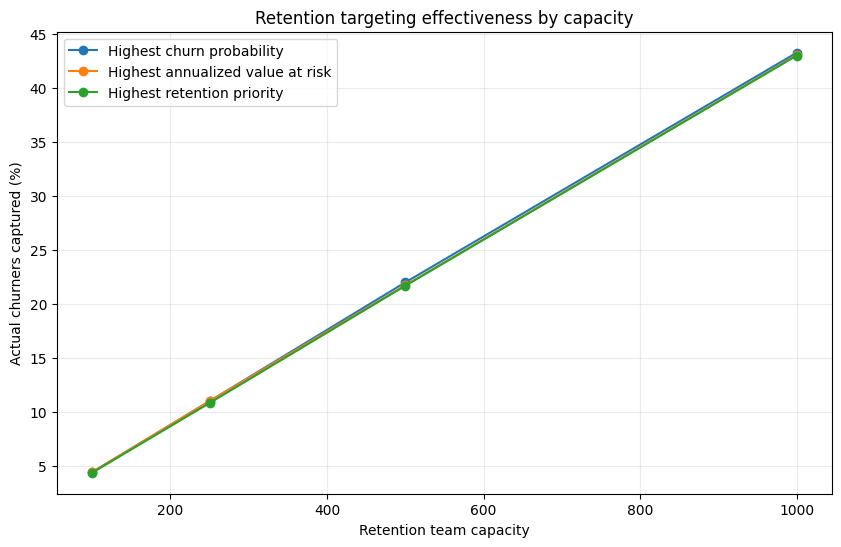

In [87]:
# Visualize churner capture by team capacity.

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for strategy in simulation["strategy"].unique():

    temp = simulation[
        simulation["strategy"] == strategy
    ]

    plt.plot(
        temp["capacity"],
        temp["churner_capture_rate"] * 100,
        marker="o",
        label=strategy
    )

plt.xlabel(
    "Retention team capacity"
)

plt.ylabel(
    "Actual churners captured (%)"
)

plt.title(
    "Retention targeting effectiveness by capacity"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.show()

In [88]:
# Show the absolute annualized subscription value of actual churners captured.

absolute_value_pivot = (
    simulation
    .pivot(
        index="capacity",
        columns="strategy",
        values="actual_churn_value_captured"
    )
)

display(
    absolute_value_pivot.round(0)
)

strategy,Highest annualized value at risk,Highest churn probability,Highest retention priority
capacity,,,
100,184378.0,136442.0,179498.0
250,452363.0,366726.0,434012.0
500,863977.0,757844.0,868095.0
1000,1720723.0,1477817.0,1709464.0


In [89]:
# Calculate lift relative to random targeting.

simulation["population_contacted_pct"] = (
    simulation["customers_contacted"]
    / len(customer)
)

simulation["lift_vs_random"] = (
    simulation["churner_capture_rate"]
    / simulation["population_contacted_pct"]
)

display(
    simulation[
        [
            "capacity",
            "strategy",
            "churner_capture_rate",
            "population_contacted_pct",
            "lift_vs_random"
        ]
    ].round(3)
)

,capacity,strategy,churner_capture_rate,population_contacted_pct,lift_vs_random
0,100,Highest churn probability,0.044,0.004,11.116
1,100,Highest annualized value at risk,0.044,0.004,11.116
2,100,Highest retention priority,0.044,0.004,11.005
3,250,Highest churn probability,0.110,0.010,11.027
4,250,Highest annualized value at risk,0.110,0.010,11.027
5,250,Highest retention priority,0.108,0.010,10.849
6,500,Highest churn probability,0.220,0.020,11.005
7,500,Highest annualized value at risk,0.217,0.020,10.871
8,500,Highest retention priority,0.217,0.020,10.849
9,1000,Highest churn probability,0.433,0.040,10.816


### 14.1 Business interpretation of the targeting trade-off

At a capacity of 500 subscribers, the model contacts only about **2% of the population** while capturing roughly **22% of observed churners** - around **11x lift over random targeting**.

Ranking by annualized value at risk captures slightly fewer churners than probability-only ranking, but materially more churn value. This creates a clear executive choice:

- maximize **number of subscribers saved** -> rank by churn probability
- maximize **economic value protected** -> rank by annualized value at risk

# Part V - Model interpretation and final outputs

## 15. Final model comparison and diagnostic plots

The following cells consolidate performance metrics, check calibration and visualize the precision-recall trade-off.

### How to read the final diagnostics

The final section intentionally uses several metrics because no single score answers every question:

- **ROC-AUC:** overall ability to rank churners above non-churners.
- **PR-AUC:** ranking quality focused on the minority churn class; especially useful at ~9% churn prevalence.
- **Log Loss:** quality of predicted probabilities, penalizing confident mistakes.
- **Calibration curve / Brier Score:** whether predicted probabilities align with observed event rates.
- **Lift / capture rate:** operational concentration of churners under limited contact capacity.
- **Value captured:** economic concentration under limited contact capacity.

The business recommendation should therefore be based on the full set of diagnostics, not on ROC-AUC alone.


In [90]:
# Compare baseline, raw LightGBM and calibrated LightGBM in one table.

model_comparison = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "log_loss": log_loss(y_test, p_logit),
        "roc_auc": roc_auc_score(y_test, p_logit),
        "pr_auc": average_precision_score(y_test, p_logit)
    },
    {
        "model": "LightGBM",
        "log_loss": log_loss(y_test, p_lgbm),
        "roc_auc": roc_auc_score(y_test, p_lgbm),
        "pr_auc": average_precision_score(y_test, p_lgbm)
    },
    {
        "model": "Calibrated LightGBM",
        "log_loss": log_loss(y_test, p_lgbm_calibrated),
        "roc_auc": roc_auc_score(y_test, p_lgbm_calibrated),
        "pr_auc": average_precision_score(y_test, p_lgbm_calibrated)
    }
])

display(
    model_comparison
    .sort_values("log_loss")
    .round(4)
)

,model,log_loss,roc_auc,pr_auc
2,Calibrated LightGBM,0.1796,0.8866,0.6628
1,LightGBM,0.2435,0.8847,0.6606
0,Logistic Regression,0.3876,0.8734,0.5999


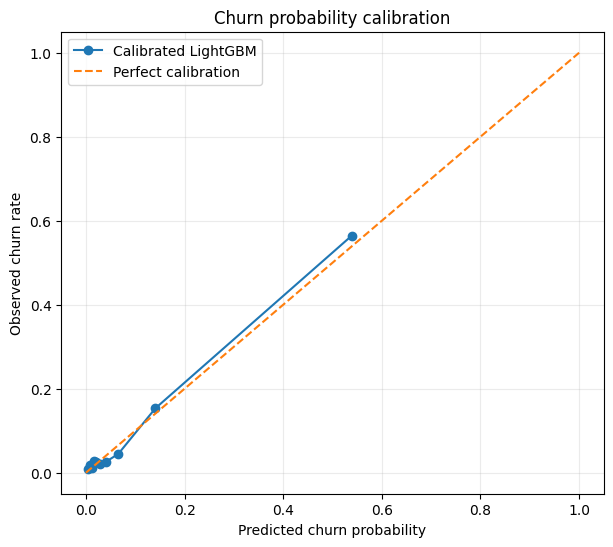

In [91]:
# Plot predicted probability against observed churn frequency.

from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_test,
    p_lgbm_calibrated,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Calibrated LightGBM"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Predicted churn probability")
plt.ylabel("Observed churn rate")
plt.title("Churn probability calibration")
plt.legend()
plt.grid(alpha=0.25)

plt.show()

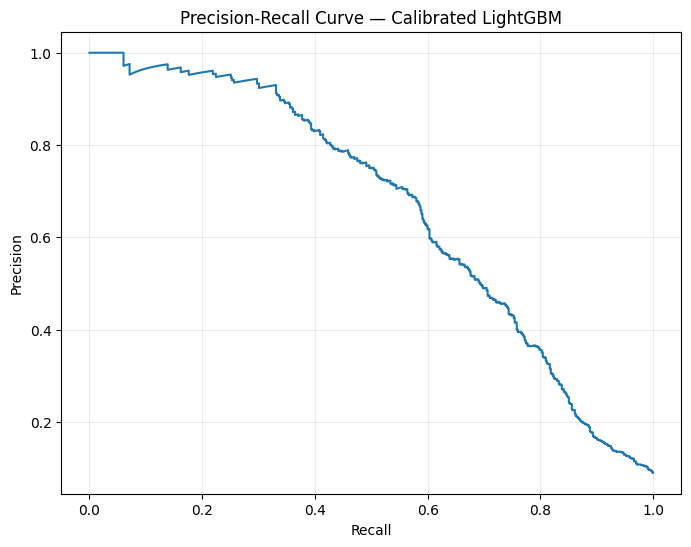

In [92]:
# Plot the precision-recall curve for the calibrated model.

from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test,
    p_lgbm_calibrated
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Calibrated LightGBM")
plt.grid(alpha=0.25)

plt.show()

## 16. Model interpretation

Two complementary importance views are retained:

- LightGBM split/gain-based feature importance for a fast global ranking
- SHAP values for direction-aware feature contribution analysis

SHAP is calculated on a manageable test subset to keep the notebook practical in Colab.

In [93]:
# Extract transformed feature names and LightGBM importance values.

prep_fitted = lgbm.named_steps["prep"]
model_fitted = lgbm.named_steps["model"]

feature_names = prep_fitted.get_feature_names_out()

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": model_fitted.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        "importance",
        ascending=False
    )
)

display(
    feature_importance.head(25)
)

,feature,importance
2,num__subscription_tenure_days,1200
1,num__registration_tenure_days,1180
22,num__days_to_expiry,1092
31,num__avg_completion_rate_30d,957
35,num__recent_vs_prior_daily_hours,856
28,num__avg_hours_active_day_30d,838
34,num__unique_songs_7d,595
29,num__unique_songs_30d,578
3,num__transaction_count,560
0,num__age_clean,560


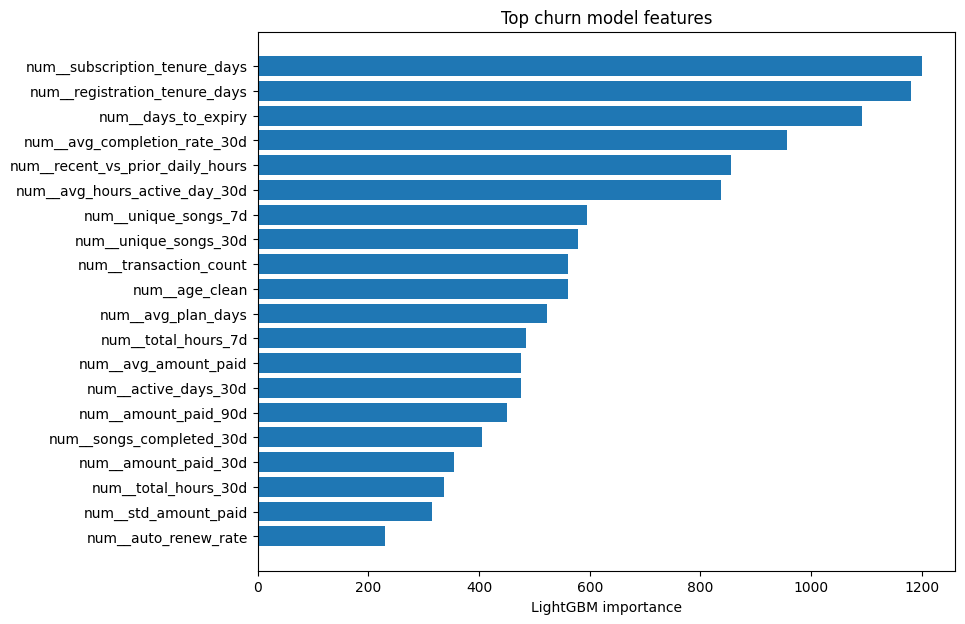

In [94]:
# Plot the top 20 LightGBM features.

top_features = feature_importance.head(20).sort_values(
    "importance"
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("LightGBM importance")
plt.title("Top churn model features")

plt.show()

In [95]:
# Remove preprocessing prefixes from feature names for presentation.

feature_importance["feature_clean"] = (
    feature_importance["feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

display(
    feature_importance[
        ["feature_clean", "importance"]
    ]
    .head(20)
)

,feature_clean,importance
2,subscription_tenure_days,1200
1,registration_tenure_days,1180
22,days_to_expiry,1092
31,avg_completion_rate_30d,957
35,recent_vs_prior_daily_hours,856
28,avg_hours_active_day_30d,838
34,unique_songs_7d,595
29,unique_songs_30d,578
3,transaction_count,560
0,age_clean,560


In [96]:
# Import SHAP (installed at the start of the notebook).

import shap

In [97]:
# Transform a representative test sample for SHAP analysis.

SHAP_SAMPLE_SIZE = 1500

X_shap = X_test.sample(
    min(SHAP_SAMPLE_SIZE, len(X_test)),
    random_state=42
)

X_shap_transformed = prep_fitted.transform(
    X_shap
)

if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()

print(
    "SHAP matrix:",
    X_shap_transformed.shape
)

SHAP matrix: (1500, 100)


In [98]:
# Build a tree explainer for the fitted LightGBM model.

explainer = shap.TreeExplainer(
    model_fitted
)

shap_values = explainer.shap_values(
    X_shap_transformed
)

In [99]:
# Handle SHAP-version differences in binary-class output format.

if isinstance(shap_values, list):
    shap_plot_values = shap_values[-1]
else:
    shap_plot_values = shap_values

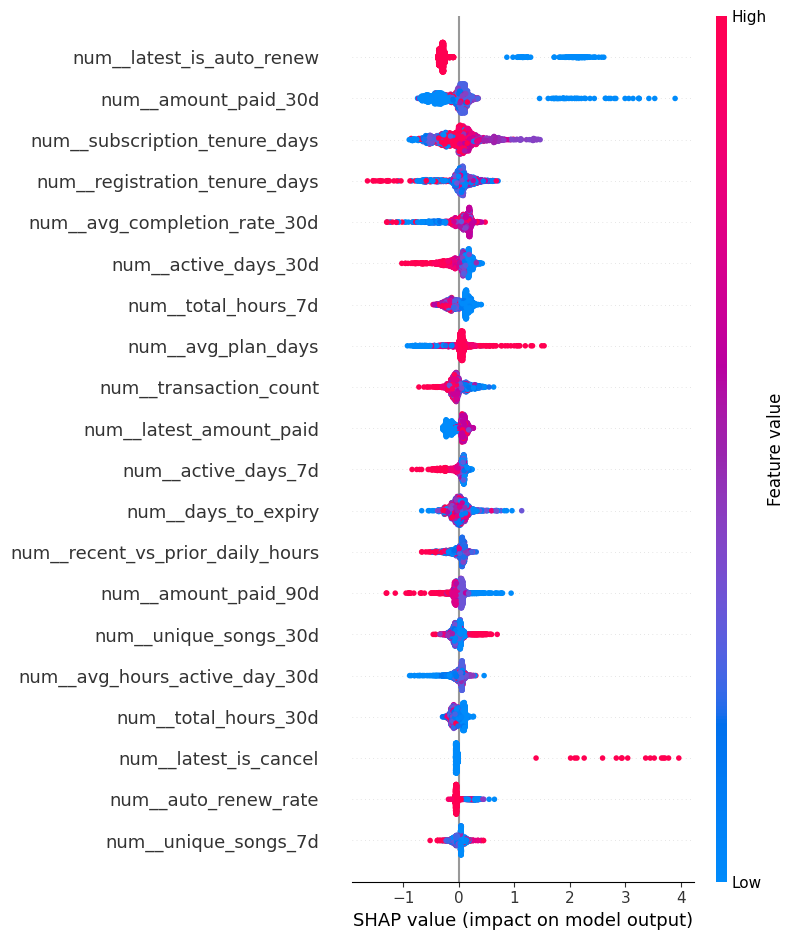

In [100]:
# Plot global SHAP feature effects.

shap.summary_plot(
    shap_plot_values,
    X_shap_transformed,
    feature_names=feature_names,
    max_display=20
)

## 17. Final targeting visuals and trade-off tables

These charts shift the discussion from model accuracy to **resource allocation**: how much churn and how much economic value can be captured for a given intervention budget?

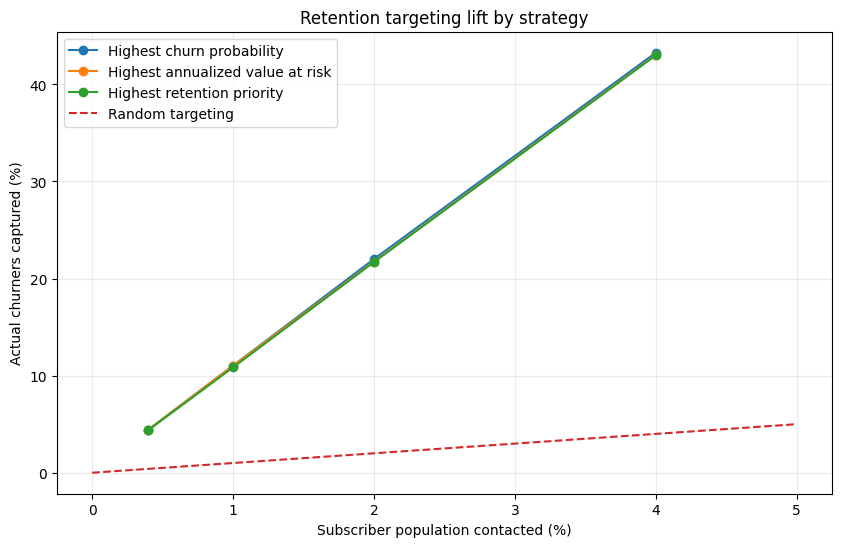

In [101]:
# Plot churn capture against the percentage of the subscriber population contacted, including a random benchmark.

plt.figure(figsize=(10, 6))

for strategy in simulation["strategy"].unique():

    temp = simulation[
        simulation["strategy"] == strategy
    ]

    plt.plot(
        temp["population_contacted_pct"] * 100,
        temp["churner_capture_rate"] * 100,
        marker="o",
        label=strategy
    )

# Random benchmark
x_random = np.linspace(0, 5, 50)

plt.plot(
    x_random,
    x_random,
    linestyle="--",
    label="Random targeting"
)

plt.xlabel("Subscriber population contacted (%)")
plt.ylabel("Actual churners captured (%)")
plt.title("Retention targeting lift by strategy")

plt.legend()
plt.grid(alpha=0.25)

plt.show()

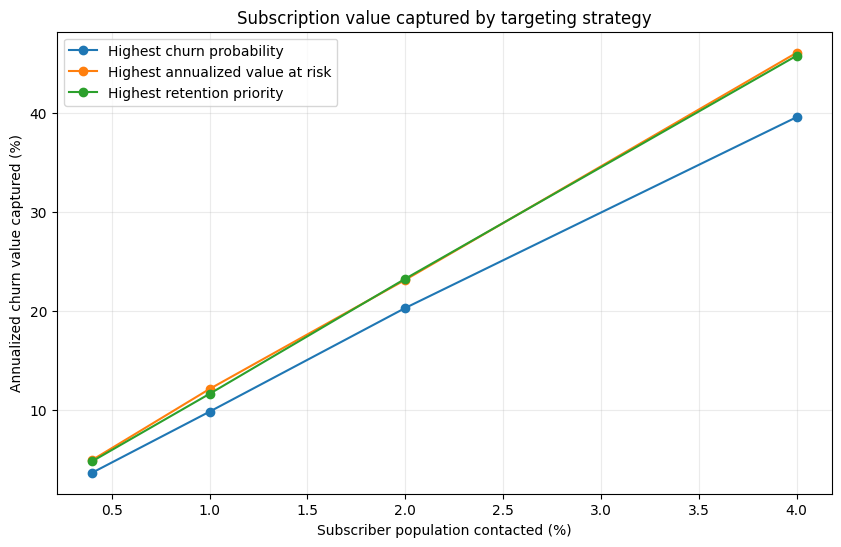

In [102]:
# Plot annualized churn value captured by strategy.

plt.figure(figsize=(10, 6))

for strategy in simulation["strategy"].unique():

    temp = simulation[
        simulation["strategy"] == strategy
    ]

    plt.plot(
        temp["population_contacted_pct"] * 100,
        temp["share_of_churn_value_captured"] * 100,
        marker="o",
        label=strategy
    )

plt.xlabel("Subscriber population contacted (%)")
plt.ylabel("Annualized churn value captured (%)")
plt.title("Subscription value captured by targeting strategy")

plt.legend()
plt.grid(alpha=0.25)

plt.show()

In [103]:
# Create a compact probability-vs-value targeting trade-off table.

tradeoff = (
    simulation[
        simulation["strategy"].isin([
            "Highest churn probability",
            "Highest annualized value at risk"
        ])
    ]
    .pivot(
        index="capacity",
        columns="strategy",
        values=[
            "churner_capture_rate",
            "share_of_churn_value_captured"
        ]
    )
)

display(
    tradeoff.round(4)
)

churner_capture_rate                            \
strategy Highest annualized value at risk Highest churn probability   
capacity                                                              
100                                0.0445                    0.0445   
250                                0.1103                    0.1103   
500                                0.2174                    0.2201   
1000                               0.4304                    0.4326   

            share_of_churn_value_captured                            
strategy Highest annualized value at risk Highest churn probability  
capacity                                                             
100                                0.0494                    0.0366  
250                                0.1212                    0.0983  
500                                0.2315                    0.2031  
1000                               0.4612                    0.3961

In [104]:
# Quantify the incremental annualized value captured by value-based ranking.

probability_strategy = simulation[
    simulation["strategy"] == "Highest churn probability"
].set_index("capacity")

value_strategy = simulation[
    simulation["strategy"] == "Highest annualized value at risk"
].set_index("capacity")

business_tradeoff = pd.DataFrame({
    "churn_capture_probability_strategy":
        probability_strategy["churner_capture_rate"],

    "churn_capture_value_strategy":
        value_strategy["churner_capture_rate"],

    "value_capture_probability_strategy":
        probability_strategy["share_of_churn_value_captured"],

    "value_capture_value_strategy":
        value_strategy["share_of_churn_value_captured"],

    "incremental_value_captured":
        value_strategy["actual_churn_value_captured"]
        - probability_strategy["actual_churn_value_captured"]
})

display(
    business_tradeoff.round(3)
)

,churn_capture_probability_strategy,churn_capture_value_strategy,value_capture_probability_strategy,value_capture_value_strategy,incremental_value_captured
capacity,,,,,
100,0.044,0.044,0.037,0.049,47935.286
250,0.110,0.110,0.098,0.121,85637.383
500,0.220,0.217,0.203,0.232,106132.979
1000,0.433,0.430,0.396,0.461,242905.504


## 18. Next-best-action layer

The final action logic converts predicted risk and engagement state into operational categories. Thresholds are illustrative and should be calibrated to real contact costs, offer economics and treatment effectiveness in production.

### What this action layer is — and is not

The recommended actions are an illustrative translation of analytical signals into operating categories. They demonstrate how analytics could feed a retention workflow, but the thresholds are **not optimized treatment rules**.

A production next-best-action system would require additional evidence such as contact cost, offer cost, channel capacity, customer lifetime value and — ideally — causal uplift estimates showing who is actually persuadable by an intervention.


In [105]:
# Define illustrative next-best-action rules.

def final_action(row):

    if row["churn_probability"] >= 0.60:

        if row["annualized_subscription_value"] >= (
            customer["annualized_subscription_value"]
            .quantile(0.75)
        ):
            return "Priority retention"

        if (
            row["engagement_trajectory"]
            == "Intermittent / Low Engagement"
        ):
            return "Re-engagement + retention"

        return "Retention outreach"

    if (
        row["churn_probability"] >= 0.30
        and row["engagement_trajectory"]
        == "Intermittent / Low Engagement"
    ):
        return "Engagement intervention"

    if row["churn_probability"] >= 0.20:
        return "Monitor"

    return "Low-touch"

In [106]:
# Apply next-best-action labels to the customer mart.

customer["final_recommended_action"] = (
    customer.apply(
        final_action,
        axis=1
    )
)

In [107]:
# Summarize subscriber count, observed churn and expected value at risk by action.

action_summary = (
    customer
    .groupby("final_recommended_action")
    .agg(
        subscribers=("msno", "count"),
        observed_churn_rate=("is_churn", "mean"),
        avg_predicted_churn=("churn_probability", "mean"),
        total_annualized_value=(
            "annualized_subscription_value",
            "sum"
        ),
        expected_value_at_risk=(
            "annualized_value_at_risk",
            "sum"
        )
    )
    .reset_index()
    .sort_values(
        "expected_value_at_risk",
        ascending=False
    )
)

display(
    action_summary.round(3)
)

,final_recommended_action,subscribers,observed_churn_rate,avg_predicted_churn,total_annualized_value,expected_value_at_risk
1,Low-touch,22046,0.012,0.034,3.444139e+07,1240197.682
2,Monitor,1302,0.446,0.333,2.246086e+06,743633.084
3,Priority retention,479,0.977,0.781,8.972123e+05,697847.760
5,Retention outreach,458,0.959,0.852,5.911615e+05,508655.453
0,Engagement intervention,530,0.609,0.438,1.000257e+06,438932.798
4,Re-engagement + retention,185,0.968,0.861,2.502910e+05,217818.577


## 19. Executive KPI summary

This table condenses the project into the metrics a commercial or retention leader would care about: model discrimination, targeting lift and incremental economic value captured.

In [108]:
# Store final calibrated-model quality metrics.

best_model_metrics = {
    "roc_auc": roc_auc_score(
        y_test,
        p_lgbm_calibrated
    ),
    "pr_auc": average_precision_score(
        y_test,
        p_lgbm_calibrated
    ),
    "log_loss": log_loss(
        y_test,
        p_lgbm_calibrated
    )
}

In [109]:
# Pull the capacity-500 results used in the executive summary.

capacity_500_value = simulation[
    (simulation["capacity"] == 500)
    &
    (
        simulation["strategy"]
        == "Highest annualized value at risk"
    )
].iloc[0]

capacity_500_prob = simulation[
    (simulation["capacity"] == 500)
    &
    (
        simulation["strategy"]
        == "Highest churn probability"
    )
].iloc[0]

In [110]:
# Build a one-table executive summary.

executive_summary = pd.DataFrame({
    "Metric": [
        "Subscribers analyzed",
        "Observed churn rate",
        "Model ROC-AUC",
        "Model PR-AUC",
        "Model Log Loss",
        "Population contacted at capacity 500",
        "Churners captured at capacity 500",
        "Lift vs random at capacity 500",
        "Churn value captured — probability ranking",
        "Churn value captured — value ranking",
        "Incremental annualized value captured"
    ],

    "Value": [
        len(customer),

        customer["is_churn"].mean(),

        best_model_metrics["roc_auc"],

        best_model_metrics["pr_auc"],

        best_model_metrics["log_loss"],

        500 / len(customer),

        capacity_500_prob["churner_capture_rate"],

        capacity_500_prob["lift_vs_random"],

        capacity_500_prob[
            "actual_churn_value_captured"
        ],

        capacity_500_value[
            "actual_churn_value_captured"
        ],

        (
            capacity_500_value[
                "actual_churn_value_captured"
            ]
            -
            capacity_500_prob[
                "actual_churn_value_captured"
            ]
        )
    ]
})

display(
    executive_summary
)

,Metric,Value
0,Subscribers analyzed,25000.000000
1,Observed churn rate,0.089960
2,Model ROC-AUC,0.886645
3,Model PR-AUC,0.662812
4,Model Log Loss,0.179646
5,Population contacted at capacity 500,0.020000
6,Churners captured at capacity 500,0.220098
7,Lift vs random at capacity 500,11.004891
8,Churn value captured — probability ranking,757844.228057
9,Churn value captured — value ranking,863977.206739


In [111]:
# Create the final segment x trajectory risk summary.

final_segment_summary = (
    customer
    .groupby(
        [
            "static_segment",
            "engagement_trajectory"
        ],
        dropna=False
    )
    .agg(
        subscribers=("msno", "count"),
        churn_rate=("is_churn", "mean"),
        avg_predicted_churn=(
            "churn_probability",
            "mean"
        ),
        median_annualized_value=(
            "annualized_subscription_value",
            "median"
        ),
        expected_value_at_risk=(
            "annualized_value_at_risk",
            "sum"
        )
    )
    .reset_index()
)

display(
    final_segment_summary
    .sort_values(
        "expected_value_at_risk",
        ascending=False
    )
    .round(3)
)

,static_segment,engagement_trajectory,subscribers,churn_rate,avg_predicted_churn,median_annualized_value,expected_value_at_risk
8,Renewal-Risk Subscribers,Consistent / High Engagement,1826,0.329,0.308,1814.075,989481.751
9,Renewal-Risk Subscribers,Intermittent / Low Engagement,1147,0.418,0.401,1814.075,844290.129
12,Stable Loyal Subscribers,Intermittent / Low Engagement,3730,0.068,0.069,1814.075,453771.278
7,Low-Usage Auto-Renew Subscribers,NaN,4004,0.055,0.082,1205.325,375748.208
11,Stable Loyal Subscribers,Consistent / High Engagement,4149,0.044,0.041,1814.075,300859.273
13,Stable Loyal Subscribers,NaN,1392,0.077,0.103,1814.075,253637.229
0,Highly Engaged Power Users,Consistent / High Engagement,2607,0.057,0.053,1814.075,243816.147
6,Low-Usage Auto-Renew Subscribers,Intermittent / Low Engagement,3832,0.032,0.038,1205.325,204324.902
5,Low-Usage Auto-Renew Subscribers,Consistent / High Engagement,2221,0.025,0.027,1205.325,83212.331
4,Lapsed / Extreme Cases,NaN,53,0.925,0.923,1814.075,57643.894


## 20. Export aggregate portfolio outputs

Raw subscriber-level KKBox records should not be redistributed. The notebook therefore exports only aggregate analytical outputs suitable for portfolio review, subject to the competition rules.

In [112]:
# Export aggregate model, segment and targeting summaries.

OUTPUT_DIR = Path(
    "/content/kkbox/portfolio_outputs"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

model_comparison.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

business_matrix.to_csv(
    OUTPUT_DIR / "segment_action_matrix.csv",
    index=False
)

simulation.to_csv(
    OUTPUT_DIR / "retention_capacity_simulation.csv",
    index=False
)

action_summary.to_csv(
    OUTPUT_DIR / "action_summary.csv",
    index=False
)

final_segment_summary.to_csv(
    OUTPUT_DIR / "final_segment_summary.csv",
    index=False
)

executive_summary.to_csv(
    OUTPUT_DIR / "executive_summary.csv",
    index=False
)

print("Saved outputs to:")
print(OUTPUT_DIR)

Saved outputs to:
/content/kkbox/portfolio_outputs


# Executive conclusions

This project combines real KKBox membership, payment and listening data to move from descriptive segmentation to economically prioritized churn intervention.

### What the analysis found

- The sampled March-2017 cohort preserves an observed churn rate of roughly **9%**.
- Static segmentation identifies a distinct **Renewal-Risk** segment with materially elevated churn.
- Engagement trajectory adds useful context inside static segments: intermittent / low engagement is associated with higher churn than consistent / high engagement in several commercial groups.
- Raw DTW clustering was tested but produced weak separation. The project therefore pivoted to engineered trajectory features, which produced a substantially stronger and more interpretable two-cluster solution.
- LightGBM outperforms logistic regression on ROC-AUC, PR-AUC and Log Loss.
- Probability calibration corrects the class-weighted LightGBM probabilities from an average around 18% to approximately the observed 9% churn rate.
- At a capacity of 500 subscribers, the model contacts only about **2%** of the population while capturing roughly **22%** of observed churners - around **11x lift over random targeting**.
- Ranking by expected annualized value at risk sacrifices only a small amount of churner capture while materially increasing the annualized subscription value represented by the captured churners.

### Business recommendation

Use **calibrated churn probability** when the operational objective is to maximize the number of subscribers saved.

Use **expected annualized subscription value at risk** when the objective is to maximize economic value protected under a constrained retention budget.

The heuristic retention-priority score is retained as an experiment but is not recommended as the headline strategy because it does not outperform the simpler value-at-risk ranking.

### The project in one sentence

**Use unsupervised customer structure to understand who subscribers are, behavioral trajectories to understand how they are behaving, calibrated machine learning to estimate individual churn risk, and value-at-risk ranking to decide where limited retention capacity should be spent.**


# Limitations and production next steps

### Limitations
- The analysis uses historical competition data rather than a live production environment.
- Annualized Subscription Value is an analytical normalization proxy, not an official KKBox accounting metric.
- The supervised model uses a stratified holdout from a single churn cohort rather than full random K-fold benchmarking. Five-fold CV is used for probability calibration; a stronger production design would validate the entire modeling pipeline on a later out-of-time cohort.
- Static and trajectory clustering use unsupervised features only, but a fully production-grade pipeline would fit clustering transformations on training data and assign held-out observations afterward.
- The retention simulation measures **who would be selected**, not who would be causally saved by intervention.
- Expected value at risk represents model-based exposure, not guaranteed recoverable revenue.

### Recommended next steps
1. Out-of-time validation using the earlier KKBox cohort.
2. Survival analysis for time-to-churn.
3. Uplift modeling to identify subscribers whose behavior is actually changed by retention treatment.
4. Explicit contact cost, offer cost and retained lifetime value in the optimization objective.
5. Production monitoring for calibration drift, feature drift and segment migration.
